# Alfamart JSM Promotion Analysis

## 1. Data Loading and Initial Inspection

In [1]:
import pymysql
import pandas as pd

In [2]:
connection = pymysql.connect(
    host="vmlp.pwdlearning.cloud",
    user="student_ds",
    password="@studentDS#2026",
    port=3306,
    cursorclass=pymysql.cursors.DictCursor,
    database="alfamart"
)

print("Koneksi berhasil!")

Koneksi berhasil!


In [3]:
cursor = connection.cursor()

cursor.execute("SHOW DATABASES")

for db in cursor.fetchall():
    print(db)

{'Database': 'alfamart'}
{'Database': 'bluebird'}
{'Database': 'dekoruma'}
{'Database': 'information_schema'}
{'Database': 'performance_schema'}
{'Database': 'sinarmasland'}
{'Database': 'tokopedia'}


In [4]:
cursor.execute("SHOW TABLES")
tables = cursor.fetchall()

print("Daftar Tabel di database alfamart:")
for table in tables:
    # Mengambil nama tabel dari dictionary atau tuple hasil fetch
    table_name = list(table.values())[0] if isinstance(table, dict) else table[0]
    print(f"- {table_name}")

Daftar Tabel di database alfamart:
- alfa_complaint_tickets
- alfa_members
- alfa_pos_transactions
- alfa_products
- alfa_stores


In [5]:
cursor.execute("USE alfamart")

cursor.execute("SHOW TABLES")
tables = cursor.fetchall()

dfs = {}

for table in tables:
    table_name = list(table.values())[0]

    # Ambil data tabel
    cursor.execute(f"SELECT * FROM `{table_name}`")
    rows = cursor.fetchall()

    # Karena fetchall() Anda menghasilkan dictionary
    df = pd.DataFrame(rows)

    # Simpan ke dictionary
    dfs[table_name] = df

    # Buat variabel dataframe otomatis
    globals()[table_name] = df

    print(
        f"{table_name:<30} "
        f"rows: {df.shape[0]:>8} | "
        f"columns: {df.shape[1]:>3}"
    )

alfa_complaint_tickets         rows:    10759 | columns:   9
alfa_members                   rows:    48214 | columns:  10
alfa_pos_transactions          rows:   455148 | columns:  12
alfa_products                  rows:      507 | columns:  11
alfa_stores                    rows:     1003 | columns:  10


In [6]:
for name, df in dfs.items():

    print("=" * 100)
    print(f"TABLE: {name}")
    print("=" * 100)

    print(f"Shape      : {df.shape}")
    print(f"Rows       : {df.shape[0]}")
    print(f"Columns    : {df.shape[1]}")
    print(f"Duplicates : {df.duplicated().sum()}")
    print(f"Total Null : {df.isnull().sum().sum()}")

    print("\nDATA INFO")
    df.info()

    print("\nCOLUMN SUMMARY")

    column_summary = pd.DataFrame({
        "dtype": df.dtypes,
        "null_count": df.isnull().sum(),
        "null_percent": (
            df.isnull().sum() / len(df) * 100
        ).round(2),
        "unique_count": df.nunique()
    })

    display(column_summary)

    print("\nSAMPLE DATA")
    display(df.head())

    print("\n")

TABLE: alfa_complaint_tickets
Shape      : (10759, 9)
Rows       : 10759
Columns    : 9
Duplicates : 0
Total Null : 2972

DATA INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10759 entries, 0 to 10758
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   ticket_id              10759 non-null  object        
 1   receipt_id             10759 non-null  object        
 2   complaint_category     10759 non-null  object        
 3   ticket_date            10759 non-null  datetime64[ns]
 4   channel                10759 non-null  object        
 5   resolution_status      10759 non-null  object        
 6   resolution_time_hours  9273 non-null   object        
 7   csat_score             9273 non-null   object        
 8   disputed_amount        10759 non-null  object        
dtypes: datetime64[ns](1), object(8)
memory usage: 756.6+ KB

COLUMN SUMMARY


,dtype,null_count,null_percent,unique_count
ticket_id,object,0,0.00,10759
receipt_id,object,0,0.00,10759
complaint_category,object,0,0.00,6
ticket_date,datetime64[ns],0,0.00,9156
channel,object,0,0.00,4
resolution_status,object,0,0.00,3
resolution_time_hours,object,1486,13.81,1068
csat_score,object,1486,13.81,5
disputed_amount,object,0,0.00,9996



SAMPLE DATA


,ticket_id,receipt_id,complaint_category,ticket_date,channel,resolution_status,resolution_time_hours,csat_score,disputed_amount
0,TCK0100000,RCP00263916,Produk Kadaluarsa/Rusak,2020-11-15 14:00:00,Langsung ke Gerai,Resolved,37.2,4.0,78287.0
1,TCK0100001,RCP00105974,Produk Kadaluarsa/Rusak,2020-12-08 22:00:00,Media Sosial,Escalated,64.0,1.0,9115.0
2,TCK0100002,RCP00148221,Antrian Lama,2020-12-08 20:00:00,Aplikasi Alfagift,Escalated,56.7,3.0,10974.0
3,TCK0100003,RCP00284125,Produk Kadaluarsa/Rusak,2020-12-12 11:00:00,Langsung ke Gerai,Resolved,19.6,3.0,119691.0
4,TCK0100004,RCP00229184,Produk Kadaluarsa/Rusak,2020-12-16 18:00:00,Call Center 1500-959,Resolved,14.9,5.0,20264.0




TABLE: alfa_members
Shape      : (48214, 10)
Rows       : 48214
Columns    : 10
Duplicates : 0
Total Null : 0

DATA INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48214 entries, 0 to 48213
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   member_id            48214 non-null  object
 1   registration_date    48214 non-null  object
 2   home_city            48214 non-null  object
 3   gender               48214 non-null  object
 4   birth_year           48214 non-null  int64 
 5   membership_tier      48214 non-null  object
 6   acquisition_channel  48214 non-null  object
 7   phone_verified       48214 non-null  int64 
 8   points_balance       48214 non-null  int64 
 9   last_active_date     48214 non-null  object
dtypes: int64(3), object(7)
memory usage: 3.7+ MB

COLUMN SUMMARY


...

,sku_id,product_name,category,brand,unit_price,unit_of_measure,is_perishable,shelf_life_days,supplier_id,is_jsm_promo,jsm_discount_pct
0,SKU000001,Air Mineral Aqua,Beverage,Danone-Aqua,12100.0,botol,0,641.0,SUP-107,1,0.31
1,SKU000002,Indm Grg,Food & Staples,Indofood,39000.0,pack,0,502.0,SUP-184,1,0.34
2,SKU000003,Bimoli Pouch 2000ml,Food & Staples,Salim Ivomas,12900.0,pack,0,599.0,SUP-162,0,0.00
3,SKU000004,Air Mineral Aqua,Beverage,Danone-Aqua,27800.0,botol,0,708.0,SUP-132,0,0.00
4,SKU000005,Rokok Sampoerna Mild,Cigarettes,Sampoerna,13800.0,pack,0,NaN,SUP-183,0,0.00




TABLE: alfa_stores
Shape      : (1003, 10)
Rows       : 1003
Columns    : 10
Duplicates : 0
Total Null : 0

DATA INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1003 entries, 0 to 1002
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   store_id           1003 non-null   object
 1   store_name         1003 non-null   object
 2   city               1003 non-null   object
 3   province           1003 non-null   object
 4   open_date          1003 non-null   object
 5   store_type         1003 non-null   object
 6   store_format       1003 non-null   object
 7   store_size_sqm     1003 non-null   int64 
 8   has_self_checkout  1003 non-null   int64 
 9   region_code        1003 non-null   object
dtypes: int64(2), object(8)
memory usage: 78.5+ KB

COLUMN SUMMARY


,dtype,null_count,null_percent,unique_count
store_id,object,0,0.0,1003
store_name,object,0,0.0,1003
city,object,0,0.0,10
province,object,0,0.0,6
open_date,object,0,0.0,622
store_type,object,0,0.0,3
store_format,object,0,0.0,3
store_size_sqm,int64,0,0.0,257
has_self_checkout,int64,0,0.0,2
region_code,object,0,0.0,24



SAMPLE DATA


,store_id,store_name,city,province,open_date,store_type,store_format,store_size_sqm,has_self_checkout,region_code
0,SAT-0001,Alfamart Sudirman 0,Depok,Jawa Barat,2022-05-08,Perkantoran,Sedang (Reguler),147,0,REG-JABAR-3
1,SAT-0002,Alfamart Diponegoro 1,Surabaya,Jawa Timur,2022-09-16,Residential/Perumahan,Sedang (Reguler),206,0,REG-JATIM-4
2,SAT-0003,Alfamart Melati 2,Depok,Jawa Barat,2022-05-24,Perkantoran,Sedang (Reguler),203,0,REG-JABAR-1
3,SAT-0004,Alfamart Sudirman 3,Tangerang,Banten,2022-05-01,Residential/Perumahan,Besar (Reguler Plus),359,0,REG-BANTEN-4
4,SAT-0005,Alfamart Melati 4,Bogor,Jawa Barat,2021-03-27,Residential/Perumahan,Kecil (Express),69,0,REG-JABAR-1


## 2. Data Cleaning and Handling

Pengecekan terhadap seluruh tabel, tahap selanjutnya melakukan cleanding dan handling tabel secara terpisah dengan memeriksa missing value, duplicate, tipe data, konsistensi kategori, validasi nilai numerik dan pengecekan jika ada anonamli sebelum data digunakan untuk analisis

Setelah melakukan initial inspection terhadap seluruh tabel, tahap berikutnya adalah melakukan data cleaning dan handling secara terpisah pada masing-masing dataset.

Proses ini mencakup pemeriksaan missing value, duplicate, tipe data, konsistensi kategori, validitas nilai numerik, serta potential data anomalies sebelum dataset digunakan untuk analisis.

### 2.1 `alfa_complaint_tickets`

Hasil pemeroksaan awal pada tabel `alfa_complaint_tickets` menunjukkan adanya missing value pada `resolution_time_hours` dan `csat_score`.

Sebelum melakukan imputasi atau penghapusan data, perlu diperiksa apakah missing value tersebut memiliki hubungan dengan status penyelesaian complaint.

In [7]:
pd.crosstab(
    alfa_complaint_tickets["resolution_status"],
    alfa_complaint_tickets["resolution_time_hours"].isna(),
    margins=True
)

resolution_time_hours,False,True,All
resolution_status,,,
Escalated,1609,0,1609
Pending,0,1486,1486
Resolved,7664,0,7664
All,9273,1486,10759


In [8]:
pd.crosstab(
    alfa_complaint_tickets["resolution_status"],
    alfa_complaint_tickets["csat_score"].isna(),
    margins=True
)

csat_score,False,True,All
resolution_status,,,
Escalated,1609,0,1609
Pending,0,1486,1486
Resolved,7664,0,7664
All,9273,1486,10759


In [9]:
alfa_complaint_tickets["resolution_status"].value_counts(dropna=False)

resolution_status
Resolved     7664
Escalated    1609
Pending      1486
Name: count, dtype: int64

hasil pemeriksaan menunjukkan bahwa missing value pada `resolution_time_hours` dan `csat_score` berkaitan dengan complaint yang masih berstatus `Pending`.

Hal ini menunjukkan bahwa missing value tersebut karena terstruktur dari pending, karena resolution time dan csat score belum tersedia untuk complaint yang belum selesai.

Oleh karena itu missing value pada kedua variabel tersebut tidak dilakukan imputasi maupun penghapusan.

In [10]:
alfa_complaint_tickets["ticket_id"].is_unique

True

In [11]:
sorted(
    alfa_complaint_tickets["complaint_category"]
    .astype(str)
    .unique()
)

['Antrian Lama',
 'Harga Tidak Sesuai Struk',
 'Kembalian Kurang',
 'Ketersediaan Stok',
 'Pelayanan Kasir',
 'Produk Kadaluarsa/Rusak']

In [12]:
alfa_complaint_tickets["ticket_date"].agg(["min", "max"])

min   2020-11-15 14:00:00
max   2025-10-14 10:00:00
Name: ticket_date, dtype: datetime64[ns]

In [13]:
alfa_complaint_tickets[
    "resolution_time_hours"
].unique()[:20]

array([Decimal('37.2'), Decimal('64.0'), Decimal('56.7'), Decimal('19.6'),
       Decimal('14.9'), Decimal('9.0'), Decimal('8.0'), Decimal('31.4'),
       Decimal('40.5'), None, Decimal('11.4'), Decimal('10.0'),
       Decimal('8.4'), Decimal('41.2'), Decimal('12.4'), Decimal('13.2'),
       Decimal('51.9'), Decimal('6.6'), Decimal('22.0'), Decimal('8.1')],
      dtype=object)

#### Numeric Data Type Conversion

Kolom `resolution_time_hours`, `csat_score`, dan `disputed_amount` masih tersimpan dalam format object. Ketiga variabel tersebut merupakan variabel numerik, sehingga perlu dikonversi sebelum digunakan untuk analisis.

In [14]:
alfa_complaint_tickets["resolution_time_hours"] = pd.to_numeric(
    alfa_complaint_tickets["resolution_time_hours"],
    errors="coerce"
)

In [15]:
alfa_complaint_tickets["resolution_time_hours"].dtype

dtype('float64')

In [16]:
alfa_complaint_tickets["csat_score"].value_counts(
    dropna=False
)

csat_score
5.0     3790
4.0     2754
None    1486
3.0     1360
1.0      824
2.0      545
Name: count, dtype: int64

In [17]:
alfa_complaint_tickets["csat_score"] = pd.to_numeric(
    alfa_complaint_tickets["csat_score"],
    errors="coerce"
)

In [18]:
alfa_complaint_tickets[
    ~alfa_complaint_tickets["csat_score"].between(1, 5)
    & alfa_complaint_tickets["csat_score"].notna()
]

,ticket_id,receipt_id,complaint_category,ticket_date,channel,resolution_status,resolution_time_hours,csat_score,disputed_amount


In [19]:
alfa_complaint_tickets["disputed_amount"] = pd.to_numeric(
    alfa_complaint_tickets["disputed_amount"],
    errors="coerce"
)

In [20]:
alfa_complaint_tickets[
    alfa_complaint_tickets["disputed_amount"] < 0
]

,ticket_id,receipt_id,complaint_category,ticket_date,channel,resolution_status,resolution_time_hours,csat_score,disputed_amount


In [21]:
missing_analysis = (
    alfa_complaint_tickets
    .groupby("resolution_status", observed=True)
    .agg(
        total_ticket=("ticket_id", "count"),
        missing_resolution_time=(
            "resolution_time_hours",
            lambda x: x.isna().sum()
        ),
        missing_csat=(
            "csat_score",
            lambda x: x.isna().sum()
        )
    )
)

missing_analysis

,total_ticket,missing_resolution_time,missing_csat
resolution_status,,,
Escalated,1609,0,0
Pending,1486,1486,1486
Resolved,7664,0,0


### Cleaning Summary — `alfa_complaint_tickets`

Hasil cleaning dan validation pada tabel `alfa_complaint_tickets` menunjukkan bahwa:

- tidak ditemukan duplicate row
- `ticket_id` bersifat unik untuk seluruh complaint
- missing value pada `resolution_time_hours` dan `csat_score` berasal dari complaint berstatus `Pending` dan diperlakukan sebagai structural missing value
- `resolution_time_hours`, `csat_score`, dan `disputed_amount` telah dikonversi menjadi tipe numeric
- tidak ditemukan nilai `csat_score` di luar rentang 1–5
- tidak ditemukan `disputed_amount` negatif
- tidak ada row yang perlu dihapus pada tahap cleaning

### 2.2 `alfa_pos_transactions`

Tabel `alfa_pos_transactions` merupakan dataset utama untuk analisis transaksi dan Promo JSM

Tahap cleaning mencakup:
- pemeriksaan missing `member_id`
- konversi tipe data numerik
- standardisasi kategori
- pemeriksaan quantity dan transaction value ekstrem
- pembentukan variabel tambahan yang diperlukan untuk analisis

In [22]:
alfa_pos_transactions.head()

,receipt_id,store_id,sku_id,member_id,trx_time,payment_method,qty,total_price,transaction_status,discount_amount,points_earned,checkout_channel
0,RCP00000001,SAT-0142,SKU000180,MEM-11847,2022-12-24 21:00:00,BCA Debit,1,33500.0,COMPLETED,0.0,3,Kasir Reguler
1,RCP00000002,SAT-0294,SKU000115,None,2022-10-25 14:00:00,Cash,2,62200.0,VOID,0.0,0,Kasir Reguler
2,RCP00000003,SAT-0623,SKU000132,None,2022-12-02 08:00:00,Tunai,3,85500.0,COMPLETED,0.0,0,Kasir Reguler
3,RCP00000004,SAT-0386,SKU000262,MEM-44261,2024-07-28 09:00:00,CASH,12,191784.0,COMPLETED,122616.0,19,Kasir Reguler
4,RCP00000005,SAT-0665,SKU000437,MEM-48359,2023-07-14 12:00:00,ShopeePay,1,12692.0,COMPLETED,4008.0,1,Kasir Reguler


In [23]:
print(
    alfa_pos_transactions['member_id']
    .isna()
    .value_counts()
)

member_id
False    301502
True     153646
Name: count, dtype: int64


#### Missing `member_id`

Missing value pada `member_id` tidak langsung dianggap sebagai error karena transaksi dapat dilakukan oleh customer member maupun non-member sehingga di pertahankan

In [24]:
import numpy as np

In [25]:
alfa_pos_transactions['customer_type'] = np.where(
    alfa_pos_transactions['member_id'].notna(),
    'Member',
    'Non-Member'
)

In [26]:
alfa_pos_transactions['customer_type'].value_counts()

customer_type
Member        301502
Non-Member    153646
Name: count, dtype: int64

In [27]:
print(
    alfa_pos_transactions['total_price']
    .astype(str)
    .str.contains(r'[^0-9.\-]', regex=True)
    .value_counts()
)

print(
    alfa_pos_transactions['discount_amount']
    .astype(str)
    .str.contains(r'[^0-9.\-]', regex=True)
    .value_counts()
)

total_price
False    455148
Name: count, dtype: int64
discount_amount
False    455148
Name: count, dtype: int64


#### Numeric Data Type Conversion

Kolom `total_price` dan `discount_amount` masih dtype sebagai object. setelah pengecekan tidak ditemukan data numerikal sehingga keduanya di convert menjadi numeric.

In [28]:
alfa_pos_transactions['total_price'] = pd.to_numeric(
    alfa_pos_transactions['total_price'],
    errors='coerce'
)

alfa_pos_transactions['discount_amount'] = pd.to_numeric(
    alfa_pos_transactions['discount_amount'],
    errors='coerce'
)

In [29]:
alfa_pos_transactions[
    ['total_price', 'discount_amount']
].dtypes

total_price        float64
discount_amount    float64
dtype: object

In [30]:
alfa_pos_transactions[
    ['total_price', 'discount_amount']
].isna().sum()

total_price        0
discount_amount    0
dtype: int64

In [31]:
print("Jumlah baris:",
      len(alfa_pos_transactions))

print("Jumlah receipt unik:",
      alfa_pos_transactions['receipt_id'].nunique())

Jumlah baris: 455148
Jumlah receipt unik: 455148


In [32]:
receipt_size = (
    alfa_pos_transactions
    .groupby('receipt_id')
    .size()
)

print(receipt_size.describe())

count    455148.0
mean          1.0
std           0.0
min           1.0
25%           1.0
50%           1.0
75%           1.0
max           1.0
dtype: float64


In [33]:
print(
    receipt_size
    .sort_values(ascending=False)
    .head(20)
)

receipt_id
RCP00000001    1
RCP00303429    1
RCP00303440    1
RCP00303439    1
RCP00303438    1
RCP00303437    1
RCP00303436    1
RCP00303435    1
RCP00303434    1
RCP00303433    1
RCP00303432    1
RCP00303431    1
RCP00303430    1
RCP00303428    1
RCP00303442    1
RCP00303427    1
RCP00303426    1
RCP00303425    1
RCP00303424    1
RCP00303423    1
dtype: int64


#### `receipt_id` Validation

Jumlah unik sama dengan jumlah row dataset sehingga tiap baris mewakili data yang ada

In [34]:
print("PAYMENT METHOD")
print(
    alfa_pos_transactions['payment_method']
    .value_counts(dropna=False)
)

print("\nTRANSACTION STATUS")
print(
    alfa_pos_transactions['transaction_status']
    .value_counts(dropna=False)
)

print("\nCHECKOUT CHANNEL")
print(
    alfa_pos_transactions['checkout_channel']
    .value_counts(dropna=False)
)

PAYMENT METHOD
payment_method
Cash         90496
CASH         60523
BCA Debit    45779
Gopay        45704
Tunai        45664
ShopeePay    45224
qris         30593
OVO          30488
debit bca    30373
QRIS         30304
Name: count, dtype: int64

TRANSACTION STATUS
transaction_status
COMPLETED    441124
VOID          14024
Name: count, dtype: int64

CHECKOUT CHANNEL
checkout_channel
Kasir Reguler            430438
Self-Checkout Mandiri     24710
Name: count, dtype: int64


#### Categorical Standardization

Kita bisa lihat bawha ada inkonsistensi inputasi pada payment method masih ada cash, bca debit dan qris yang berulang padahal masih sama maksud. sedang kan transaction_status dan checkout channel tidak ada

In [35]:
payment_mapping = {
    'Cash': 'Cash',
    'CASH': 'Cash',
    'Tunai': 'Cash',
    'BCA Debit': 'BCA Debit',
    'debit bca': 'BCA Debit',
    'Gopay': 'GoPay',
    'ShopeePay': 'ShopeePay',
    'qris': 'QRIS',
    'QRIS': 'QRIS',
    'OVO': 'OVO'
}

alfa_pos_transactions['payment_method'] = (
    alfa_pos_transactions['payment_method']
    .map(payment_mapping)
)

In [36]:
alfa_pos_transactions['payment_method'].value_counts()

payment_method
Cash         196683
BCA Debit     76152
QRIS          60897
GoPay         45704
ShopeePay     45224
OVO           30488
Name: count, dtype: int64

In [37]:
alfa_pos_transactions[
    ['qty', 'total_price', 'discount_amount', 'points_earned']
].describe()

,qty,total_price,discount_amount,points_earned
count,455148.000000,4.551480e+05,4.551480e+05,455148.000000
mean,16.060624,3.655186e+05,2.382300e+04,27.498317
std,238.285278,6.256414e+06,5.894629e+05,590.217173
min,-7.000000,-3.129000e+05,-1.048040e+05,0.000000
25%,1.000000,2.340800e+04,0.000000e+00,0.000000
50%,2.000000,4.240000e+04,0.000000e+00,2.000000
75%,4.000000,1.005000e+05,0.000000e+00,7.000000
max,9992.000000,4.402944e+08,1.495703e+08,64862.000000


In [38]:
print("qty <= 0:",
      (alfa_pos_transactions['qty'] <= 0).sum())

print("total_price < 0:",
      (alfa_pos_transactions['total_price'] < 0).sum())

print("discount_amount < 0:",
      (alfa_pos_transactions['discount_amount'] < 0).sum())

print("discount_amount > total_price:",
      (
          alfa_pos_transactions['discount_amount']
          > alfa_pos_transactions['total_price']
      ).sum())

print("points_earned < 0:",
      (alfa_pos_transactions['points_earned'] < 0).sum())

qty <= 0: 1483
total_price < 0: 1483
discount_amount < 0: 104
discount_amount > total_price: 1483
points_earned < 0: 0


Statistik deskriptif menunjukkan beberapa nilai yang memerlukan pemeriksaan lebih lanjut

Beberapa temuan awal meliputi:
- median `qty` relatif kecil, tetapi nilai maksimum mencapai ribuan unit
- `total_price`, `discount_amount`, dan `points_earned` juga memiliki nilai maksimum yang jauh di atas mayoritas transaksi
- terdapat transaksi dengan `qty <= 0` dan `total_price < 0`

Nilai tersebut belum langsung dihapus perlu diperiksa konteks transaksinya terlebih dahulu

In [39]:
pd.crosstab(
    alfa_pos_transactions['transaction_status'],
    alfa_pos_transactions['qty'] <= 0
)

qty,False,True
transaction_status,,
COMPLETED,439675,1449
VOID,13990,34


In [40]:
pd.crosstab(
    alfa_pos_transactions['transaction_status'],
    alfa_pos_transactions['total_price'] < 0
)

total_price,False,True
transaction_status,,
COMPLETED,439675,1449
VOID,13990,34


In [41]:
alfa_pos_transactions[
    alfa_pos_transactions['qty'] <= 0
][
    [
        'receipt_id',
        'qty',
        'total_price',
        'discount_amount',
        'points_earned',
        'transaction_status'
    ]
].head(20)

,receipt_id,qty,total_price,discount_amount,points_earned,transaction_status
23,RCP00000024,-7,-305900.0,0.0,0,COMPLETED
762,RCP00000763,-4,-121600.0,0.0,0,COMPLETED
840,RCP00000841,-6,-208800.0,0.0,0,COMPLETED
884,RCP00000885,-4,-108400.0,0.0,0,COMPLETED
923,RCP00000924,-2,-84400.0,0.0,0,COMPLETED
1220,RCP00001221,-4,-166800.0,0.0,0,COMPLETED
1368,RCP00001369,-7,-158900.0,0.0,0,COMPLETED
1574,RCP00001575,-7,-213500.0,0.0,0,COMPLETED
1643,RCP00001644,-7,-283500.0,0.0,0,COMPLETED
1768,RCP00001769,-5,-128500.0,0.0,0,COMPLETED


#### Assesmen transaksi negatif

Transaksi dengan `qty < 0` dan `total_price < 0` tidak seluruhnya memiliki status `VOID`. Sebagian  tercatat sebagai `COMPLETED`

Kesamaan arah antara quantity negatif dan nilai transaksi negatif mengindikasikan bahwa record tersebut kemungkinan merepresentasikan proses return atau refund

dibuatkan variabel transction type untuk membedakan transaksi penjualan dengan kemungkinan return/refund

In [42]:
alfa_pos_transactions['transaction_type'] = np.where(
    alfa_pos_transactions['qty'] < 0,
    'Return/Refund',
    'Sale'
)

In [43]:
alfa_pos_transactions['transaction_type'].value_counts()

transaction_type
Sale             453665
Return/Refund      1483
Name: count, dtype: int64

In [44]:
print("qty < 0:",
      (alfa_pos_transactions['qty'] < 0).sum())

print("qty == 0:",
      (alfa_pos_transactions['qty'] == 0).sum())

qty < 0: 1483
qty == 0: 0


In [45]:
positive_transactions = alfa_pos_transactions[
    alfa_pos_transactions['total_price'] >= 0
]

(
    positive_transactions['discount_amount']
    > positive_transactions['total_price']
).sum()

0

Untuk transaksi dengan `total_price >= 0`, tidak ditemukan kasus `discount_amount > total_price`

oleh karna itu tidak terdapat indikasi diskon positif yang melebihi nilai transakdi

#### pengecekan nilai ekstrim

Selanjutnya dilakukan pemeriksaan terhadap transaksi dengan nilai `qty`, `total_price`, `discount_amount`, dan `points_earned` yang sangat tinggi.

Untuk menentukan apakah nilai ekstrem tersebut merupakan transaksi dengan volume tinggi yang masih konsisten secara matematis atau merupakan kemungkinan quantity anomaly

In [46]:
alfa_pos_transactions[
    [
        'receipt_id',
        'store_id',
        'sku_id',
        'qty',
        'total_price',
        'discount_amount',
        'points_earned',
        'transaction_status'
    ]
].sort_values(
    'qty',
    ascending=False
).head(20)

,receipt_id,store_id,sku_id,qty,total_price,discount_amount,points_earned,transaction_status
197585,RCP00197586,SAT-0273,SKU000416,9992,388688800.0,0.0,38869,VOID
195803,RCP00195804,SAT-0716,SKU000362,9981,267490800.0,0.0,0,VOID
109595,RCP00109596,SAT-0162,SKU000266,9975,95760000.0,0.0,0,COMPLETED
64059,RCP00064060,SAT-0031,SKU000440,9966,177394800.0,0.0,0,VOID
255227,RCP00255228,SAT-0365,SKU000479,9946,37794800.0,0.0,3779,VOID
26075,RCP00026076,SAT-0265,SKU000465,9912,291412800.0,0.0,58282,VOID
29001,RCP00029002,SAT-0938,SKU000316,9907,278386700.0,0.0,55678,VOID
149632,RCP00149633,SAT-0696,SKU000150,9885,419124000.0,0.0,0,VOID
35567,RCP00035568,SAT-0425,SKU000180,9849,329941500.0,0.0,32994,VOID
278264,RCP00278265,SAT-0886,SKU000287,9847,224511600.0,0.0,22451,VOID


In [47]:
alfa_pos_transactions[
    [
        'receipt_id',
        'store_id',
        'sku_id',
        'qty',
        'total_price',
        'discount_amount',
        'points_earned',
        'transaction_status'
    ]
].sort_values(
    'total_price',
    ascending=False
).head(20)

,receipt_id,store_id,sku_id,qty,total_price,discount_amount,points_earned,transaction_status
213577,RCP00213578,SAT-0294,SKU000146,9828,440294400.0,0.0,44029,COMPLETED
149632,RCP00149633,SAT-0696,SKU000150,9885,419124000.0,0.0,0,VOID
64351,RCP00064352,SAT-0954,SKU000317,9378,415445400.0,0.0,41545,COMPLETED
257923,RCP00257924,SAT-0696,SKU000333,9374,403082000.0,0.0,40308,VOID
165677,RCP00165678,SAT-0705,SKU000427,9671,401346500.0,0.0,0,COMPLETED
35178,RCP00035179,SAT-0306,SKU000204,9814,399429800.0,0.0,39943,VOID
159224,RCP00159225,SAT-0045,SKU000496,9122,393158200.0,0.0,0,COMPLETED
197585,RCP00197586,SAT-0273,SKU000416,9992,388688800.0,0.0,38869,VOID
61736,RCP00061737,SAT-0429,SKU000469,9430,384744000.0,0.0,38474,VOID
294669,RCP00294670,SAT-0222,SKU000449,9029,376509300.0,0.0,0,VOID


In [48]:
alfa_pos_transactions['unit_price'] = (
    alfa_pos_transactions['total_price']
    / alfa_pos_transactions['qty']
)

In [49]:
alfa_pos_transactions['unit_price'].describe()

count    455148.000000
mean      23601.441439
std       11880.743034
min        2622.000000
25%       14200.000000
50%       23000.000000
75%       33400.000000
max       44800.000000
Name: unit_price, dtype: float64

Perhitungan `unit_price = total_price / qty` menunjukkan bahwa nilai unit price tetap berada pada rentang harga produk yang masuk akal.

hal ini menunjukkan bahwa total nilai transaksi yang sangat besar terutama dipengaruhi oleh qty yang sangat tinggi, bukan karena unit price yang tidak wajar

namun, konsistensi matematis tersebut belum cukup untuk memastikan bahwa quantity ekstrem valid secara bisnis.

In [50]:
sku_unit_price = (
    alfa_pos_transactions[
        alfa_pos_transactions['qty'] > 0
    ]
    .groupby('sku_id')['unit_price']
    .agg(['count', 'min', 'median', 'max'])
)

sku_unit_price.head(20)

,count,min,median,max
sku_id,,,,
SKU000001,1093,8349.0,8349.0,12100.0
SKU000002,1138,25740.0,25740.0,39000.0
SKU000003,793,12900.0,12900.0,12900.0
SKU000004,843,27800.0,27800.0,27800.0
SKU000005,862,13800.0,13800.0,13800.0
SKU000006,832,15100.0,15100.0,15100.0
SKU000007,853,29600.0,29600.0,29600.0
SKU000008,796,3900.0,3900.0,3900.0
SKU000009,1123,28014.0,28014.0,40600.0


In [51]:
alfa_pos_transactions[
    alfa_pos_transactions['sku_id'] == 'SKU000146'
][
    [
        'receipt_id',
        'qty',
        'total_price',
        'unit_price',
        'transaction_status'
    ]
].sort_values('qty', ascending=False).head(20)

,receipt_id,qty,total_price,unit_price,transaction_status
213577,RCP00213578,9828,440294400.0,44800.0,COMPLETED
283421,RCP00283422,7542,337881600.0,44800.0,VOID
54948,RCP00054949,5780,258944000.0,44800.0,VOID
139324,RCP00139325,1728,77414400.0,44800.0,VOID
114266,RCP00114267,1227,54969600.0,44800.0,VOID
59701,RCP00059702,999,44755200.0,44800.0,VOID
20295,RCP00020296,999,44755200.0,44800.0,VOID
96963,RCP00096964,24,1075200.0,44800.0,COMPLETED
172879,RCP00172880,24,1075200.0,44800.0,COMPLETED
165854,RCP00165855,24,1075200.0,44800.0,COMPLETED


Pemeriksaan unit price dan pola harga per SKU menunjukkan bahwa transaksi dengan quantity sangat tinggi tetap konsisten secara matematis dengan harga produk

namun nilai quantity hingga ribuan unit sangat berbeda dari pola transaksi mayoritas dan tidak dapat dinyatakan valid hanya berdasarkan konsistensi harga.

Oleh karena itu:
- transaksi ekstrem tetap dipertahankan 
- nilai quantity ekstrem akan diperlakukan sebagai data yang dicurigai anomali pada tahap analisis
- threshold untuk analisis perilaku akan ditentukan berdasarkan distribusi quantity, bukan dengan menghapus data 

In [52]:
alfa_pos_transactions['qty'].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
)

0.500       2.000
0.750       4.000
0.900      12.000
0.950      28.000
0.990      80.000
0.995      87.000
0.999    4040.942
Name: qty, dtype: float64

In [53]:
print("qty > 10:",
      (alfa_pos_transactions['qty'] > 10).sum())

print("qty > 50:",
      (alfa_pos_transactions['qty'] > 50).sum())

print("qty > 100:",
      (alfa_pos_transactions['qty'] > 100).sum())

print("qty > 500:",
      (alfa_pos_transactions['qty'] > 500).sum())

print("qty > 1000:",
      (alfa_pos_transactions['qty'] > 1000).sum())

qty > 10: 57032
qty > 50: 14910
qty > 100: 1517
qty > 500: 1493
qty > 1000: 690


#### Summary distribusi kuantiti 

Distribusi menunjukkan bahwa mayoritas transaksi memiliki jumlah unit yang rendah, sedangkan transaksi dengan quantity sangat tinggi hanya mencakup sebagian kecil data.

Temuan ini mendukung pemisahan
- pola pembelian reguler
- pembelian dengan volum tinggi
- kuantiti ekstrim yang memerlukan pemeriksaan khusus

### Handling summary `alfa_pos_transactions`

Tahap cleaning tabel transaksi menghasilkan beberapa hasil
- missing `member_id` dipertahankan dan digunakan untuk membedakan transaksi Member dan Non-Member
- `total_price` dan `discount_amount` dikonversi menjadi numeric
- variasi penulisan `payment_method` distandardisasi
- transaksi dengan nilai negatif tidak langsung dihapus dan ditandai sebagai kemungkinan `Return/Refund`
- kuantiti ekstrim tetap dipertahankan pada master dataset karena konsistensi matematis harga masih terjaga
- kuantiti ekstrim tidak dianggap otomatis valid maupun sebagai akan ditangani melalui analisis pada tahap berikutnya.

### 2.3 `alfa_members`

Kolom `registration_date` dan `last_active_date` masih tersimpan sebagai object, harus kita rubah menjadi datetime

In [54]:
alfa_members['registration_date'] = pd.to_datetime(
    alfa_members['registration_date'],
    errors='coerce'
)

alfa_members['last_active_date'] = pd.to_datetime(
    alfa_members['last_active_date'],
    errors='coerce'
)

In [55]:
alfa_members['member_id'].nunique()

48214

`member_id` memiliki jumlah unique yang sama dengan total row, sehingga setiap member

In [56]:
for col in [
    'home_city',
    'gender',
    'membership_tier',
    'acquisition_channel'
]:
    print(f"\n{col}")
    print(alfa_members[col].value_counts(dropna=False))


home_city
home_city
Jakarta      4934
Bandung      4906
Tangerang    4856
Surabaya     4848
Medan        4837
Malang       4811
Bekasi       4810
Depok        4783
Semarang     4737
Bogor        4692
Name: count, dtype: int64

gender
gender
P    24140
L    24074
Name: count, dtype: int64

membership_tier
membership_tier
Reguler    42634
Gold        5580
Name: count, dtype: int64

acquisition_channel
acquisition_channel
Aplikasi Alfagift    26588
Daftar di Toko       19330
Website               2296
Name: count, dtype: int64


Pengecekan kategori pada `home_city`, `gender`, `membership_tier`, dan `acquisition_channel` tidak ditemukan inkonsistensi penulisan atau kategori yang memerlukan standardisasi

In [57]:
alfa_members[
    ['birth_year', 'phone_verified', 'points_balance']
].describe()

,birth_year,phone_verified,points_balance
count,48214.000000,48214.000000,48214.000000
mean,1985.419360,0.822666,25045.357531
std,12.125407,0.381955,14431.802111
min,1965.000000,0.000000,2.000000
25%,1975.000000,1.000000,12495.500000
50%,1985.000000,1.000000,25178.000000
75%,1996.000000,1.000000,37548.000000
max,2006.000000,1.000000,49999.000000


Nilai `birth_year` berada pada rentang 1965–2006. Variabel `phone_verified` memiliki nilai biner 0 dan 1, sedangkan `points_balance` tidak memiliki nilai negatif.

Tidak ditemukan nilai numerik yang memerlukan koreksi atau penghapusan.

In [58]:
print(
    alfa_members['phone_verified'].value_counts()
)

print(
    "Negative points:",
    (alfa_members['points_balance'] < 0).sum()
)

phone_verified
1    39664
0     8550
Name: count, dtype: int64
Negative points: 0


In [59]:
print(
    alfa_members['birth_year'].min(),
    alfa_members['birth_year'].max()
)

1965 2006


In [60]:
(
    alfa_members['last_active_date']
    < alfa_members['registration_date']
).sum()

0

In [61]:
alfa_members.dtypes

member_id                      object
registration_date      datetime64[ns]
home_city                      object
gender                         object
birth_year                      int64
membership_tier                object
acquisition_channel            object
phone_verified                  int64
points_balance                  int64
last_active_date       datetime64[ns]
dtype: object

### Summary cleaning `alfa_members`

Hasil cleaning pada tabel member menunjukkan bahwa:
- tidak ditemukan missing value maupun duplicate row
- `member_id` bersifat unik
- `registration_date` dan `last_active_date` telah dikonversi menjadi datetime
- tidak ditemukan inkonsistensi kategori yang memerlukan standardisasi
- `birth_year`, `phone_verified`, dan `points_balance` berada pada rentang yang konsisten
- tidak ditemukan `last_active_date` yang lebih awal daripada `registration_date`

Tidak ada row yang perlu dihapus pada tahap cleaning.

### 2.4 `alfa_products`

In [62]:
alfa_products.isna().sum()

sku_id                0
product_name          0
category              0
brand                 0
unit_price            0
unit_of_measure       0
is_perishable         0
shelf_life_days     105
supplier_id           0
is_jsm_promo          0
jsm_discount_pct      0
dtype: int64

In [63]:
pd.crosstab(
    alfa_products['is_perishable'],
    alfa_products['shelf_life_days'].isna()
)

shelf_life_days,False,True
is_perishable,,
0,378,105
1,24,0


#### Missing `shelf_life_days`

Sebanyak 105 missing value ditemukan pada `shelf_life_days`

Hasil cross-tab menunjukkan bahwa seluruh missing value tersebut berasal dari produk non-perishable (`is_perishable = 0`). Oleh karena itu missing value tersebut diperlakukan sebagai structural missing value dan tidak dilakukan imputasi.

kolom `shelf_life_days` kemudian dikonversi menjadi nullable integer (`Int64`) agar nilai valid tidak ditampilkan dalam format desimal

In [64]:
alfa_products['shelf_life_days'] = (
    alfa_products['shelf_life_days']
    .astype('Int64')
)

In [65]:
print(
    alfa_products['unit_price']
    .astype(str)
    .str.contains(r'[^0-9.\-]', regex=True)
    .value_counts()
)

unit_price
False    507
Name: count, dtype: int64


In [66]:
alfa_products['unit_price'].sample(20)

423     4100.0
403    26900.0
42     38400.0
52     18200.0
126    19100.0
379    17200.0
435    38600.0
438    29800.0
89     23600.0
124    44100.0
72     38800.0
345    43900.0
25     26300.0
68     15800.0
274    32100.0
276    26800.0
98     37100.0
214    25300.0
180    23600.0
150     4500.0
Name: unit_price, dtype: object

In [67]:
alfa_products['unit_price'] = pd.to_numeric(
    alfa_products['unit_price'],
    errors='coerce'
)

In [68]:
print(alfa_products['unit_price'].dtype)
print(alfa_products['unit_price'].isna().sum())

float64
0


#### Validasi Product Price 

Kolom `unit_price` tidak mengandung karakter non-numeric maupun format yang tidak konsisten

Setelah konversi menjadi numeric, tidak ditemukan missing value baru. Sehingga `unit_price` dapat digunakan sebagai master product price pada tahap validation berikutnya.

In [69]:
alfa_products['jsm_discount_pct'].value_counts(
    dropna=False
).sort_index()

jsm_discount_pct
0.00    413
0.15      1
0.16      2
0.17      1
0.18      5
0.19      2
0.20      3
0.21      4
0.22      2
0.23      6
0.24      3
0.25      7
0.26      4
0.27      4
0.28      2
0.29      3
0.30      4
0.31      8
0.32      6
0.33      4
0.34      5
0.36      3
0.37      3
0.38      6
0.39      5
0.40      1
Name: count, dtype: int64

In [70]:
print(
    alfa_products['jsm_discount_pct']
    .astype(str)
    .str.contains(r'[^0-9.\-]', regex=True)
    .value_counts()
)

jsm_discount_pct
False    507
Name: count, dtype: int64


In [71]:
alfa_products['jsm_discount_pct'] = pd.to_numeric(
    alfa_products['jsm_discount_pct'],
    errors='coerce'
)

In [72]:
print(alfa_products['jsm_discount_pct'].dtype)
print(alfa_products['jsm_discount_pct'].isna().sum())

float64
0


#### Validasi JSM Discount

Nilai `jsm_discount_pct` memiliki format numerik dan merepresentasikan persentase diskon dalam bentuk desimal

Setelah dikonversi menjadi numeric, tidak ditemukan missing value baru. Selanjutnya dilakukan validasi hubungan antara `is_jsm_promo` dan `jsm_discount_pct`.

In [73]:
pd.crosstab(
    alfa_products['is_jsm_promo'],
    alfa_products['jsm_discount_pct']
)

jsm_discount_pct,0.00,0.15,0.16,0.17,0.18,0.19,0.20,0.21,0.22,0.23,...,0.30,0.31,0.32,0.33,0.34,0.36,0.37,0.38,0.39,0.40
is_jsm_promo,,,,,,,,,,,,,,,,,,,,,
0,413,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,2,1,5,2,3,4,2,6,...,4,8,6,4,5,3,3,6,5,1


In [74]:
print(
    alfa_products
    .groupby('is_jsm_promo')['jsm_discount_pct']
    .agg(['count', 'min', 'max', 'mean'])
)

              count   min  max      mean
is_jsm_promo                            
0               413  0.00  0.0  0.000000
1                94  0.15  0.4  0.283404


Hasil validasi menunjukkan hubungan yang konsisten antara status Promo JSM dan persentase diskon:
- produk dengan `is_jsm_promo = 0` memiliki `jsm_discount_pct = 0`
- produk dengan `is_jsm_promo = 1` memiliki persentase diskon positif

Tidak ditemukan ketidaksesuaian antara kedua variabel tersebut

In [75]:
for col in [
    'category',
    'brand',
    'unit_of_measure'
]:
    print(f"\n{col.upper()}")
    print(
        alfa_products[col]
        .value_counts(dropna=False)
        .sort_index()
    )


CATEGORY
category
Beverage           96
Cigarettes        105
Food & Staples    205
Personal Care     101
Name: count, dtype: int64

BRAND
brand
Danone-Aqua          94
Food Station          1
Gudang Garam          1
Indofood             91
Kapal Api Global      1
Mayora                1
Salim Ivomas        111
Sampoerna           104
Ultrajaya             1
Unilever            101
Wings Food            1
Name: count, dtype: int64

UNIT_OF_MEASURE
unit_of_measure
botol     96
pack     310
pcs      101
Name: count, dtype: int64


Pada pengecekan ini tidak ditemukan inkonsistensi kategori yang memerlukan standardisasi pada `category`, `brand`, dan `unit_of_measure`.

In [76]:
print(
    alfa_products['product_name']
    .str.strip()
    .str.lower()
    .nunique()
)

print(
    alfa_products['product_name']
    .nunique()
)

18
20


#### Standarisasi Product Name 

Jumlah unique `product_name` berkurang setelah normalisasi huruf dan spasi, yang menunjukkan adanya variasi penulisan untuk produk yang sebenarnya sama

Oleh karena itu, dilakukan pemeriksaan lebih lanjut terhadap variasi nama produk sebelum standardisasi

In [77]:
normalized_name = (
    alfa_products['product_name']
    .str.strip()
    .str.lower()
)

alfa_products[
    normalized_name.duplicated(keep=False)
][
    [
        'sku_id',
        'product_name',
        'brand',
        'category'
    ]
].sort_values(
    'product_name'
)

,sku_id,product_name,brand,category
251,SKU000252,AQ btl 600,Danone-Aqua,Beverage
416,SKU000417,AQ btl 600,Danone-Aqua,Beverage
237,SKU000238,AQ btl 600,Danone-Aqua,Beverage
410,SKU000411,AQ btl 600,Danone-Aqua,Beverage
19,SKU000020,AQ btl 600,Danone-Aqua,Beverage
...,...,...,...,...
228,SKU000229,Rokok Sampoerna Mild,Sampoerna,Cigarettes
164,SKU000165,Rokok Sampoerna Mild,Sampoerna,Cigarettes
467,SKU000468,Rokok Sampoerna Mild,Sampoerna,Cigarettes
68,SKU000069,Rokok Sampoerna Mild,Sampoerna,Cigarettes


In [78]:
product_name_check = (
    alfa_products
    .assign(product_name_normalized=normalized_name)
    .groupby('product_name_normalized')['product_name']
    .unique()
)

product_name_check[
    product_name_check.apply(len) > 1
]

product_name_normalized
pepsodent 190g                      [PEPSODENT 190G, Pepsodent 190g]
rokok sampoerna mild    [Rokok Sampoerna Mild, ROKOK SAMPOERNA MILD]
Name: product_name, dtype: object

In [79]:
product_name_mapping = {
    'PEPSODENT 190G': 'Pepsodent 190g',
    'Pepsodent 190g': 'Pepsodent 190g',

    'Rokok Sampoerna Mild': 'Rokok Sampoerna Mild',
    'ROKOK SAMPOERNA MILD': 'Rokok Sampoerna Mild'
}

alfa_products['product_name'] = (
    alfa_products['product_name']
    .replace(product_name_mapping)
)

In [80]:
print(
    alfa_products['product_name']
    .str.strip()
    .str.lower()
    .nunique()
)

print(
    alfa_products['product_name']
    .nunique()
)

18
18


In [81]:
print("Unique SKU:",
      alfa_products['sku_id'].nunique())

print("Total rows:",
      len(alfa_products))

Unique SKU: 507
Total rows: 507


In [82]:
print(
    alfa_products[
        ['unit_price', 'jsm_discount_pct']
    ].describe()
)

         unit_price  jsm_discount_pct
count    507.000000        507.000000
mean   24473.767258          0.052544
std    11953.852398          0.113967
min     3200.000000          0.000000
25%    15100.000000          0.000000
50%    24000.000000          0.000000
75%    34600.000000          0.000000
max    44800.000000          0.400000


In [83]:
print(
    "unit_price <= 0:",
    (alfa_products['unit_price'] <= 0).sum()
)

print(
    "jsm_discount_pct < 0:",
    (alfa_products['jsm_discount_pct'] < 0).sum()
)

print(
    "jsm_discount_pct > 1:",
    (alfa_products['jsm_discount_pct'] > 1).sum()
)

unit_price <= 0: 0
jsm_discount_pct < 0: 0
jsm_discount_pct > 1: 0


In [84]:
print("Unique SKU:",
      alfa_products['sku_id'].nunique())

print("Total rows:",
      len(alfa_products))

print("\nis_perishable:")
print(
    alfa_products['is_perishable']
    .value_counts(dropna=False)
)

print("\nis_jsm_promo:")
print(
    alfa_products['is_jsm_promo']
    .value_counts(dropna=False)
)

Unique SKU: 507
Total rows: 507

is_perishable:
is_perishable
0    483
1     24
Name: count, dtype: int64

is_jsm_promo:
is_jsm_promo
0    413
1     94
Name: count, dtype: int64


### Cleaning Summary `alfa_products`

Hasil cleaning pada tabel produk menunjukkan bahwa:
- missing `shelf_life_days` merupakan structural missing value pada produk non-perishable
- `unit_price` dan `jsm_discount_pct` telah dikonversi menjadi numeric
- tidak ditemukan unit price non-positive maupun persentase diskon di luar rentang 0–1
- hubungan antara `is_jsm_promo` dan `jsm_discount_pct` konsisten
- kategori produk, brand, dan unit of measure tidak memerlukan standardisasi
- variasi kapitalisasi pada `product_name` telah distandardisasi
- seluruh `sku_id` tetap unik

### 2.5 `alfa_stores`

kolom `open_date` masih tersimpan sebagai object, sehingga dikonversi menjadi datetime.

In [85]:
alfa_stores['open_date'] = pd.to_datetime(
    alfa_stores['open_date'],
    errors='coerce'
)

In [86]:
print(alfa_stores['open_date'].dtype)
print("Invalid/missing date:",
      alfa_stores['open_date'].isna().sum())

datetime64[ns]
Invalid/missing date: 0


In [87]:
print("Unique store_id:",
      alfa_stores['store_id'].nunique())

print("Total rows:",
      len(alfa_stores))

Unique store_id: 1003
Total rows: 1003


In [88]:
categorical_cols = [
    'city',
    'province',
    'store_type',
    'store_format',
    'region_code'
]

for col in categorical_cols:
    print(f"\n{col.upper()}")
    print(
        alfa_stores[col]
        .value_counts(dropna=False)
        .sort_index()
    )


CITY
city
Bandung       98
Bekasi       100
Bogor         98
Depok        104
Jakarta       89
Malang       105
Medan        116
Semarang     100
Surabaya      93
Tangerang    100
Name: count, dtype: int64

PROVINCE
province
Banten            100
DKI Jakarta        89
Jawa Barat        400
Jawa Tengah       100
Jawa Timur        198
Sumatera Utara    116
Name: count, dtype: int64

STORE_TYPE
store_type
Dekat Pasar/Grosir        79
Perkantoran              163
Residential/Perumahan    761
Name: count, dtype: int64

STORE_FORMAT
store_format
Besar (Reguler Plus)    142
Kecil (Express)         235
Sedang (Reguler)        626
Name: count, dtype: int64

REGION_CODE
region_code
REG-BANTEN-1     29
REG-BANTEN-2     21
REG-BANTEN-3     27
REG-BANTEN-4     23
REG-JABAR-1     101
REG-JABAR-2      85
REG-JABAR-3      97
REG-JABAR-4     117
REG-JATENG-1     27
REG-JATENG-2     31
REG-JATENG-3     24
REG-JATENG-4     18
REG-JATIM-1      57
REG-JATIM-2      45
REG-JATIM-3      52
REG-JATIM-4      4

In [89]:
alfa_stores['has_self_checkout'].value_counts(
    dropna=False
)

has_self_checkout
0    823
1    180
Name: count, dtype: int64

In [90]:
alfa_stores['store_size_sqm'].describe()

count    1003.000000
mean      169.822532
std        70.643820
min        60.000000
25%       122.500000
50%       165.000000
75%       201.000000
max       399.000000
Name: store_size_sqm, dtype: float64

In [91]:
print(
    "store_size_sqm <= 0:",
    (alfa_stores['store_size_sqm'] <= 0).sum()
)

store_size_sqm <= 0: 0


In [92]:
print(
    "Earliest open date:",
    alfa_stores['open_date'].min()
)

print(
    "Latest open date:",
    alfa_stores['open_date'].max()
)

Earliest open date: 2021-01-05 00:00:00
Latest open date: 2025-01-20 00:00:00


### Cleaning Summary `alfa_stores`

Hasil cleaning pada tabel store menunjukkan bahwa:
- tidak ditemukan missing value maupun duplicate row
- seluruh `store_id` bersifat unik
- `open_date` telah dikonversi menjadi datetime tanpa menghasilkan invalid date;
- kategori pada `city`, `province`, `store_type`, `store_format`, dan `region_code` konsisten
- `has_self_checkout` memiliki nilai biner yang valid
- tidak ditemukan `store_size_sqm <= 0`

lalu akan di lakukan pengecekan antara tanggal transaksi dan tanggal pembukaan store 

## 3. Cleaned Master Dataset

Seluruh proses data cleaning dan handling pada masing-masing tabel telah selesai

In [93]:
alfa_complaint_tickets_clean = alfa_complaint_tickets.copy()
alfa_members_clean = alfa_members.copy()
alfa_products_clean = alfa_products.copy()
alfa_stores_clean = alfa_stores.copy()
alfa_pos_transactions_clean = alfa_pos_transactions.copy()

In [94]:
alfa_complaint_tickets_clean.to_csv(
    'alfa_complaint_tickets_clean.csv',
    index=False
)

alfa_members_clean.to_csv(
    'alfa_members_clean.csv',
    index=False
)

alfa_products_clean.to_csv(
    'alfa_products_clean.csv',
    index=False
)

alfa_stores_clean.to_csv(
    'alfa_stores_clean.csv',
    index=False
)

alfa_pos_transactions_clean.to_csv(
    'alfa_pos_transactions_clean.csv',
    index=False
)

## 4. Cross-Table Validation

Pemeriksaan selanjutnya adalah terhadap:
- `store_id` pada transaksi terhadap `alfa_stores`
- `sku_id` pada transaksi terhadap `alfa_products`
- `member_id` yang terisi terhadap `alfa_members`

In [95]:
store_not_found = (
    ~alfa_pos_transactions['store_id']
    .isin(alfa_stores['store_id'])
)

print(
    "Store ID tidak ditemukan:",
    store_not_found.sum()
)

sku_not_found = (
    ~alfa_pos_transactions['sku_id']
    .isin(alfa_products['sku_id'])
)

print(
    "SKU ID tidak ditemukan:",
    sku_not_found.sum()
)


member_not_found = (
    alfa_pos_transactions['member_id'].notna()
    &
    ~alfa_pos_transactions['member_id']
    .isin(alfa_members['member_id'])
)

print(
    "Member ID tidak ditemukan:",
    member_not_found.sum()
)

Store ID tidak ditemukan: 0
SKU ID tidak ditemukan: 0
Member ID tidak ditemukan: 0


Hasil validasi menunjukkan bahwa seluruh `store_id`, `sku_id`, dan `member_id` yang terisi pada tabel transaksi memiliki pasangan yang valid pada masing-masing master table

Validasi berikutnya adalah memastikan bahwa transaksi tidak tercatat sebelum tanggal resmi pembukaan store

Data transaksi digabungkan dengan master store menggunakan `store_id`, kemudian tanggal transaksi dibandingkan dengan `open_date`

In [96]:
store_open_check = (
    alfa_pos_transactions[
        ['receipt_id', 'store_id', 'trx_time']
    ]
    .merge(
        alfa_stores[
            ['store_id', 'open_date']
        ],
        on='store_id',
        how='left'
    )
)

In [97]:
print(
    "Store ID not found:",
    store_open_check['open_date'].isna().sum()
)

Store ID not found: 0


In [98]:
store_open_check['trx_before_open'] = (
    store_open_check['trx_time'].dt.normalize()
    < store_open_check['open_date']
)

print(
    "Transaction before store open:",
    store_open_check['trx_before_open'].sum()
)

Transaction before store open: 9000


In [99]:
store_open_check['days_before_open'] = (
    store_open_check['open_date']
    - store_open_check['trx_time'].dt.normalize()
).dt.days

In [100]:
store_open_check.loc[
    store_open_check['trx_before_open'],
    'days_before_open'
].describe()

count    9000.000000
mean       55.837111
std        26.146635
min        11.000000
25%        33.000000
50%        56.000000
75%        79.000000
max       100.000000
Name: days_before_open, dtype: float64

In [101]:
print(
    "Jumlah store terdampak:",
    store_open_check.loc[
        store_open_check['trx_before_open'],
        'store_id'
    ].nunique()
)

Jumlah store terdampak: 1000


In [102]:
store_open_check.loc[
    store_open_check['trx_before_open']
].groupby(
    ['store_id', 'open_date']
).size().sort_values(
    ascending=False
).head(20)

store_id  open_date 
SAT-0657  2021-12-12    21
SAT-0851  2022-10-07    20
SAT-0201  2021-02-01    19
SAT-0664  2023-04-30    19
SAT-0665  2022-06-22    19
SAT-0233  2021-09-13    19
SAT-0248  2022-08-18    19
SAT-0386  2023-08-02    18
SAT-0934  2021-06-12    18
SAT-0076  2022-09-08    18
SAT-0952  2021-11-23    17
SAT-0818  2023-06-28    17
SAT-0990  2022-04-29    17
SAT-0379  2021-08-05    17
SAT-0365  2022-12-23    16
SAT-0898  2022-08-28    16
SAT-0132  2021-04-02    16
SAT-0434  2021-02-17    16
SAT-0809  2023-01-29    16
SAT-0901  2023-08-09    16
dtype: int64

In [103]:
store_open_check.loc[
    store_open_check['trx_before_open'],
    [
        'receipt_id',
        'store_id',
        'trx_time',
        'open_date',
        'days_before_open'
    ]
].sort_values(
    'days_before_open',
    ascending=False
).head(20)

,receipt_id,store_id,trx_time,open_date,days_before_open
299949,RCP00299950,SAT-0596,2023-03-18 16:00:00,2023-06-26,100
95098,RCP00095099,SAT-0400,2021-04-01 12:00:00,2021-07-10,100
178501,RCP00178502,SAT-0305,2022-11-24 05:00:00,2023-03-04,100
125688,RCP00125689,SAT-0686,2020-11-25 10:00:00,2021-03-05,100
96140,RCP00096141,SAT-0192,2022-08-03 13:00:00,2022-11-11,100
257409,RCP00257410,SAT-0094,2021-12-14 03:00:00,2022-03-24,100
42097,RCP00042098,SAT-0993,2020-10-29 10:00:00,2021-02-06,100
15040,RCP00015041,SAT-0113,2021-01-06 09:00:00,2021-04-16,100
173925,RCP00173926,SAT-0767,2021-04-09 15:00:00,2021-07-18,100
257980,RCP00257981,SAT-0263,2021-10-30 03:00:00,2022-02-07,100


Ditemukan 9.000 transaksi yang tercatat sebelum tanggal resmi pembukaan store

Transaksi tersebut tersebar pada 1.000 dari 1.003 store, dengan selisih waktu sekitar 11 hingga 100 hari sebelum tanggal pembukaan** dan median sekitar 56 hari

Data tetap dipertahankan pada cleaned master dataset untuk keperluan pengecekan

In [104]:
invalid_receipts = store_open_check.loc[
    store_open_check['trx_before_open'],
    'receipt_id'
]

alfa_pos_transactions['invalid_pre_open_transaction'] = (
    alfa_pos_transactions['receipt_id']
    .isin(invalid_receipts)
)

In [105]:
alfa_pos_transactions[
    'invalid_pre_open_transaction'
].value_counts()

invalid_pre_open_transaction
False    446148
True       9000
Name: count, dtype: int64

karena analisis ditetapkan untuk periode 1 Januari 2021 hingga 31 Agustus 2025 maka dilakukan pemeriksaan apakah terdapat transaksi yang terjadi sebelum atau setelah periode analisis tersebut

In [106]:
print(
    "Earliest transaction:",
    alfa_pos_transactions['trx_time'].min()
)

print(
    "Latest transaction:",
    alfa_pos_transactions['trx_time'].max()
)

Earliest transaction: 2020-10-01 16:00:00
Latest transaction: 2025-11-15 00:00:00


In [107]:
analysis_start = pd.Timestamp('2021-01-01')
analysis_end = pd.Timestamp('2025-08-31 23:59:59')

In [108]:
outside_analysis_period = (
    (alfa_pos_transactions['trx_time'] < analysis_start)
    |
    (alfa_pos_transactions['trx_time'] > analysis_end)
)

print(
    "Transaction outside analysis period:",
    outside_analysis_period.sum()
)

Transaction outside analysis period: 571


In [109]:
print(
    "Before Jan 2021:",
    (alfa_pos_transactions['trx_time'] < analysis_start).sum()
)

print(
    "After Aug 2025:",
    (alfa_pos_transactions['trx_time'] > analysis_end).sum()
)

Before Jan 2021: 457
After Aug 2025: 114


In [110]:
alfa_pos_transactions['outside_analysis_period'] = (
    (alfa_pos_transactions['trx_time'] < analysis_start)
    |
    (alfa_pos_transactions['trx_time'] > analysis_end)
)

In [111]:
alfa_pos_transactions[
    'outside_analysis_period'
].value_counts()

outside_analysis_period
False    454577
True        571
Name: count, dtype: int64

Setelah validasi selesai, analisis dataset transaksi dibentuk dengan mengecualikan:
1. transaksi yang terjadi sebelum tanggal resmi pembukaan store
2. transaksi yang berada di luar periode analisis 1 Januari 2021–31 Agustus 2025

In [112]:
alfa_pos_transactions_analysis = (
    alfa_pos_transactions[
        (~alfa_pos_transactions['invalid_pre_open_transaction'])
        &
        (~alfa_pos_transactions['outside_analysis_period'])
    ]
    .copy()
)

In [113]:
print(
    "Raw rows:",
    len(alfa_pos_transactions)
)

print(
    "Analysis rows:",
    len(alfa_pos_transactions_analysis)
)

print(
    "Analysis period:",
    alfa_pos_transactions_analysis['trx_time'].min(),
    "to",
    alfa_pos_transactions_analysis['trx_time'].max()
)

Raw rows: 455148
Analysis rows: 446034
Analysis period: 2021-01-06 21:00:00 to 2025-08-31 00:00:00


In [114]:
print(
    "Pre-open only:",
    (
        alfa_pos_transactions['invalid_pre_open_transaction']
        &
        ~alfa_pos_transactions['outside_analysis_period']
    ).sum()
)

print(
    "Outside period only:",
    (
        ~alfa_pos_transactions['invalid_pre_open_transaction']
        &
        alfa_pos_transactions['outside_analysis_period']
    ).sum()
)

print(
    "Both:",
    (
        alfa_pos_transactions['invalid_pre_open_transaction']
        &
        alfa_pos_transactions['outside_analysis_period']
    ).sum()
)

Pre-open only: 8543
Outside period only: 114
Both: 457


In [115]:
alfa_pos_transactions_analysis.shape

(446034, 17)

In [116]:
alfa_pos_transactions.shape

(455148, 17)

Dari total 455.148 transaksiditemukan:
- 8.543 transaksi yang hanya termasuk kategori pre-opening
- 114 transaksi yang hanya berada di luar periode analisis
- 457 transaksi yang sekaligus merupakan transaksi pre-opening dan berada di luar periode analisis

Secara total 9.114 transaksi dikeluarkan dari analytical dataset sehingga analytical dataset terdiri dari 446.034 transaksi

Record yang dikeluarkan tetap tersedia pada cleaned master dataset melalui flag `invalid_pre_open_transaction` dan `outside_analysis_period`.

In [117]:
alfa_pos_transactions_analysis.to_csv(
    'alfa_pos_transactions_analysis.csv',
    index=False
)

Transaction Price Validation

Validasi berikutnya dilakukan untuk memastikan bahwa nilai transaksi konsisten dengan harga produk pada master table

Selisih antara transaction value dan expected gross price kemudian diperiksa untuk menentukan apakah perbedaan tersebut dapat dijelaskan oleh `discount_amount`

In [118]:
price_check = (
    alfa_pos_transactions_analysis
    .merge(
        alfa_products[
            ['sku_id', 'unit_price', 'is_jsm_promo', 'jsm_discount_pct']
        ],
        on='sku_id',
        how='left',
        suffixes=('_trx', '_master')
    )
)

In [119]:
price_check['expected_gross_price'] = (
    price_check['qty']
    * price_check['unit_price_master']
)

In [120]:
price_check['price_difference'] = (
    price_check['total_price']
    - price_check['expected_gross_price']
)

In [121]:
price_check['price_difference'].describe()

count    4.460340e+05
mean    -2.409447e+04
std      5.922605e+05
min     -1.495703e+08
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.048040e+05
Name: price_difference, dtype: float64

In [122]:
print(
    "Sama dengan master:",
    (price_check['price_difference'] == 0).sum()
)

print(
    "Berbeda dari master:",
    (price_check['price_difference'] != 0).sum()
)

Sama dengan master: 390716
Berbeda dari master: 55318


In [123]:
price_check['difference_explained_by_discount'] = (
    price_check['price_difference']
    == -price_check['discount_amount']
)

price_check['difference_explained_by_discount'].value_counts()

difference_explained_by_discount
True    446034
Name: count, dtype: int64

In [124]:
different_price = price_check[
    price_check['price_difference'] != 0
]

different_price[
    'difference_explained_by_discount'
].value_counts()

difference_explained_by_discount
True    55318
Name: count, dtype: int64

Sebanyak 55.318 transaksi memiliki nilai `total_price` yang berbeda dari expected gross price berdasarkan `qty × unit_price_master`. Namun seluruh perbedaan tersebut dapat dijelaskan oleh `discount_amount`. Sehingga perbedaan antara gross master price dan transaction value tidak langsung dianggap sebagai anomali harg

In [125]:
price_check['expected_net_price'] = (
    price_check['expected_gross_price']
    - price_check['discount_amount']
)

price_check['net_price_difference'] = (
    price_check['total_price']
    - price_check['expected_net_price']
)

In [126]:
print(
    "Cocok setelah diskon:",
    (price_check['net_price_difference'] == 0).sum()
)

print(
    "Masih berbeda:",
    (price_check['net_price_difference'] != 0).sum()
)

Cocok setelah diskon: 446034
Masih berbeda: 0


Setelah `discount_amount` diperhitungkan, seluruh 446.034 transaksi memiliki nilai transaksi yang sesuai dengan expected net price. Sehingga tidak ditemukan unexplained price discrepancy pada analytical dataset

Validasi terakhir dilakukan untuk memastikan bahwa Promo JSM diterapkan sesuai aturan
- hanya produk yang terdaftar sebagai JSM yang mendapatkan diskon
- diskon diberikan pada Jumat, Sabtu, dan Minggu
- nilai diskon sesuai dengan persentase promo pada master product

In [127]:
pd.crosstab(
    price_check['is_jsm_promo'],
    price_check['discount_amount'] > 0
)

discount_amount,False,True
is_jsm_promo,,
0,343951,0
1,46865,55218


Hasil pemeriksaan menunjukkan bahwa tidak terdapat produk non-JSM yang menerima `discount_amount > 0`

lalu validasi hari transaksi untuk memastikan bahwa diskon JSM hanya diberikan pada Jumat, Sabtu, dan Minggu

In [128]:
price_check['day_name'] = (
    price_check['trx_time']
    .dt.day_name()
)

price_check['is_jsm_day'] = (
    price_check['trx_time']
    .dt.dayofweek >= 4
)

In [129]:
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

pd.crosstab(
    price_check['day_name'],
    price_check['discount_amount'] > 0
).reindex(day_order)

discount_amount,False,True
day_name,,
Monday,59458,0
Tuesday,58905,0
Wednesday,59065,0
Thursday,58993,0
Friday,51463,18496
Saturday,51499,18300
Sunday,51433,18422


Seluruh transaksi dengan diskon positif terjadi pada Jumat, Sabtu, atau Minggu

Lalu untuk memastikan validasi Promo JSM tidak dipengaruhi oleh transaksi VOID atau return/refund, pemeriksaan berikutnya dibatasi pada transaksi `COMPLETED` dengan `qty > 0`

In [130]:
jsm_validation = price_check[
    (price_check['transaction_status'] == 'COMPLETED')
    &
    (price_check['qty'] > 0)
].copy()

In [131]:
print(
    "Jumlah transaksi untuk validasi JSM:",
    len(jsm_validation)
)

Jumlah transaksi untuk validasi JSM: 430898


In [132]:
jsm_products_only = jsm_validation[
    jsm_validation['is_jsm_promo'] == 1
].copy()

In [133]:
pd.crosstab(
    jsm_products_only['is_jsm_day'],
    jsm_products_only['discount_amount'] > 0
)

discount_amount,False,True
is_jsm_day,,
False,45569,0
True,0,54016


Pada transaksi valid (`COMPLETED` dan `qty > 0`), produk JSM hanya menerima diskon pada JSM Day

Selanjutnya dilakukan pemeriksaan apakah nominal diskon sesuai dengan `qty × unit_price_master × jsm_discount_pct`

In [134]:
jsm_products_only['expected_jsm_discount'] = (
    jsm_products_only['qty']
    * jsm_products_only['unit_price_master']
    * jsm_products_only['jsm_discount_pct']
)

In [135]:
jsm_products_only['discount_match'] = np.isclose(
    jsm_products_only['discount_amount'],
    jsm_products_only['expected_jsm_discount'],
    atol=1
)

In [136]:
jsm_products_only['discount_match'].value_counts()

discount_match
True     54016
False    45569
Name: count, dtype: int64

In [137]:
jsm_day_transactions = jsm_products_only[
    jsm_products_only['is_jsm_day']
].copy()

In [138]:
jsm_day_transactions['expected_jsm_discount'] = (
    jsm_day_transactions['qty']
    * jsm_day_transactions['unit_price_master']
    * jsm_day_transactions['jsm_discount_pct']
)

jsm_day_transactions['discount_match'] = np.isclose(
    jsm_day_transactions['discount_amount'],
    jsm_day_transactions['expected_jsm_discount'],
    atol=1
)

jsm_day_transactions['discount_match'].value_counts()

discount_match
True    54016
Name: count, dtype: int64

Seluruh validasi lintas tabel menunjukkan hasil yang konsisten:
- transaksi pre-opening telah ditandai dan dikeluarkan dari analytical dataset
- analytical dataset dibatasi pada periode Januari 2021–Agustus 2025
- seluruh transaction value dapat direkonsiliasi dengan master product price dan discount amount
- hanya produk JSM yang menerima diskon
- diskon JSM hanya terjadi pada Jumat–Minggu
- nominal diskon sesuai dengan persentase Promo JSM pada master product

## 5. Behavior analysis JSM

5.1 JSM Day vs Non-JSM Day

Analisis behavioral dibatasi pada transaksi valid dengan status yang `COMPLETED` dan `qty > 0`

Transaksi kemudian dibedakan menjadi:
- JSM Day
- Non-JSM Day

Untuk membandingkan pola quantity purchase antara hari promo dan hari non-promo.

In [139]:
sales_final = price_check[
    (price_check['transaction_status'] == 'COMPLETED')
    &
    (price_check['qty'] > 0)
].copy()

In [140]:
sales_final['promo_period'] = np.where(
    sales_final['is_jsm_day'],
    'JSM Day',
    'Non-JSM Day'
)

In [141]:
sales_final.groupby(
    'promo_period'
)['qty'].describe()

,count,mean,std,min,25%,50%,75%,max
promo_period,,,,,,,,
JSM Day,202727.0,10.078549,100.400636,1.0,1.0,2.0,5.0,9803.0
Non-JSM Day,228171.0,6.667412,113.830139,1.0,1.0,2.0,4.0,9975.0


Pada seluruh produk rata-rata quantity per transaksi lebih tinggi pada JSM Day dibandingkan Non-JSM Day

nilai mean dipengaruhi oleh beberapa quantity ekstrem. Oleh karena itu median, quartile, dan distribusi khusus produk JSM perlu diperiksa sebelum menarik kesimpulan mengenai perilaku pembelian

In [142]:
sales_final[
    sales_final['is_jsm_promo'] == 1
].groupby(
    'promo_period'
)['qty'].describe()

,count,mean,std,min,25%,50%,75%,max
promo_period,,,,,,,,
JSM Day,54016.0,23.221749,86.220182,1.0,2.0,5.0,41.0,8145.0
Non-JSM Day,45569.0,10.468520,114.563344,1.0,1.0,2.0,5.0,9771.0


In [143]:
sales_final[
    sales_final['is_jsm_promo'] == 1
].groupby(
    'promo_period'
)['qty'].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995]
).unstack()

,0.500,0.750,0.900,0.950,0.990,0.995
promo_period,,,,,,
JSM Day,5.0,41.0,70.0,79.0,88.0,89.0
Non-JSM Day,2.0,5.0,24.0,52.0,82.0,86.0


In [144]:
sales_final['suspected_bulk'] = (
    sales_final['qty'] > 100
)

In [145]:
pd.crosstab(
    sales_final['promo_period'],
    sales_final['suspected_bulk']
)

suspected_bulk,False,True
promo_period,,
JSM Day,202600,127
Non-JSM Day,227988,183


In [146]:
pd.crosstab(
    sales_final[
        sales_final['is_jsm_promo'] == 1
    ]['promo_period'],
    sales_final[
        sales_final['is_jsm_promo'] == 1
    ]['suspected_bulk']
)

suspected_bulk,False,True
promo_period,,
JSM Day,53993,23
Non-JSM Day,45535,34


Pada data ini terlihat bahwa memang transaksi pada JSM day sangat meningkat drastis dibanding non JSM day. Nilai median naik dari 2 menjadi 5, bahkan pada persentil 75 terlihat peningkatan dari 5 menjadi 41. 

Pada suspected bulk ditemukan bahwa transaksi yang qty >100 ternyata tidak lebih banyak daripada <= 100

In [147]:
sales_final['suspected_qty_anomaly'] = (
    sales_final['qty'] > 100
)

Berdasarkan distribusi kuantitas pembelian produk JSM, transaksi dengan qty > 100 sangat jarang dan tidak terkonsentrasi pada hari JSM. Oleh karena itu, threshold >100 lebih tepat diperlakukan sebagai suspected quantity anomaly daripada indikator pembelian bulk.

selanjutnya dilakukan analisis beberapa threshold kuantitas untuk melihat pada batas berapa pola pembelian high-volume mulai menunjukkan perbedaan yang jelas antara JSM Day dan Non-JSM Day.

5.2 Threshold Analysis for High-Volume Purchase

Analisis selanjutnya dilakukan untuk menentukan batas quantity yang dapat membedakan pembelian reguler dengan pembelian volume tinggi

Karena tujuan analisis bukan hanya mencari transaksi yang sangat ekstrem, beberapa threshold quantity dibandingkan pada JSM Day dan Non-JSM Day

Fokus utama adalah melihat bagaimana proporsi transaksi berubah ketika threshold dinaikkan secara bertahap

In [148]:
thresholds = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

jsm_sales = sales_final[
    sales_final['is_jsm_promo'] == 1
].copy()

threshold_rates = []

for threshold in thresholds:
    temp = (
        jsm_sales
        .groupby('promo_period')['qty']
        .apply(lambda x: (x > threshold).mean() * 100)
    )

    threshold_rates.append({
        'threshold': threshold,
        'JSM Day (%)': temp.get('JSM Day', 0),
        'Non-JSM Day (%)': temp.get('Non-JSM Day', 0)
    })

threshold_rates = pd.DataFrame(threshold_rates)

threshold_rates

,threshold,JSM Day (%),Non-JSM Day (%)
0,10,41.982005,16.588031
1,20,37.201940,12.495337
2,30,30.104043,7.911080
3,40,25.105524,6.535145
4,50,19.908916,5.227238
5,60,14.806724,3.846913
6,70,9.610116,2.420505
7,80,4.519031,1.145516
8,90,0.042580,0.074612
9,100,0.042580,0.074612


In [149]:
threshold_counts = []

for threshold in thresholds:
    temp = (
        jsm_sales
        .groupby('promo_period')['qty']
        .apply(lambda x: (x > threshold).sum())
    )

    threshold_counts.append({
        'threshold': threshold,
        'JSM Day': temp.get('JSM Day', 0),
        'Non-JSM Day': temp.get('Non-JSM Day', 0)
    })

threshold_counts = pd.DataFrame(threshold_counts)

threshold_counts

,threshold,JSM Day,Non-JSM Day
0,10,22677,7559
1,20,20095,5694
2,30,16261,3605
3,40,13561,2978
4,50,10754,2382
5,60,7998,1753
6,70,5191,1103
7,80,2441,522
8,90,23,34
9,100,23,34


Threshold analysis menunjukkan bahwa proporsi transaksi dengan quantity tinggi meningkat secara konsisten pada JSM Day dibandingkan Non-JSM Day

Perbedaan tersebut terlihat pada berbagai threshold, terutama pada rentang 10–80 unit. Oleh karena itu, pemilihan threshold tidak hanya didasarkan pada nilai ekstrem, tetapi juga pada perubahan distribusi transaksi antara periode promo dan non-promo.

In [150]:
threshold_comparison = threshold_rates.copy()

threshold_comparison['Gap (%)'] = (
    threshold_comparison['JSM Day (%)']
    - threshold_comparison['Non-JSM Day (%)']
)

threshold_comparison['JSM_vs_NonJSM_Ratio'] = (
    threshold_comparison['JSM Day (%)']
    / threshold_comparison['Non-JSM Day (%)']
)

threshold_comparison

,threshold,JSM Day (%),Non-JSM Day (%),Gap (%),JSM_vs_NonJSM_Ratio
0,10,41.982005,16.588031,25.393974,2.530861
1,20,37.201940,12.495337,24.706603,2.977266
2,30,30.104043,7.911080,22.192963,3.805301
3,40,25.105524,6.535145,18.570380,3.841617
4,50,19.908916,5.227238,14.681678,3.808688
5,60,14.806724,3.846913,10.959810,3.848988
6,70,9.610116,2.420505,7.189610,3.970293
7,80,4.519031,1.145516,3.373516,3.944976
8,90,0.042580,0.074612,-0.032032,0.570684
9,100,0.042580,0.074612,-0.032032,0.570684


Hasil perbandingan menunjukkan bahwa pembelian dengan `qty > 40` terjadi jauh lebih sering pada JSM Day dibandingkan Non-JSM Day

Sekitar seperempat transaksi produk JSM pada JSM Day memiliki quantity di atas 40 unit, sedangkan pada Non-JSM Day proporsinya hanya sekitar 6%

Kemudian transaksi dengan quantity di atas 90 unit sangat jarang pada kedua periode. Terdapat penurunan proporsi yang sangat tajam dari threshold 80 ke 90 unit

Berdasarkan pola tersebut, threshold 40 dan 90 digunakan sebagai batas analitik untuk membedakan regular purchase, high-volume purchase, dan suspected quantity anomaly

5.3 Purchase Volume Classification

Berdasarkan distribusi quantity dan threshold analysis, transaksi produk JSM diklasifikasikan menjadi tiga kelompok analitik
- Regular Purchase: `qty <= 40`
- High-Volume Purchase: `qty 41–90`
- Suspected Quantity Anomaly: `qty > 90`

Klasifikasi ini digunakan sebagai kerangka analitik untuk mempelajari pola pembelian dan tidak digunakan sebagai definisi langsung reseller, fraud, atau penyalahgunaan promo

In [151]:
jsm_sales['volume_category'] = np.select(
    [
        jsm_sales['qty'] <= 40,
        (jsm_sales['qty'] > 40) & (jsm_sales['qty'] <= 90),
        jsm_sales['qty'] > 90
    ],
    [
        'Regular Purchase',
        'High-Volume Purchase',
        'Suspected Qty Anomaly'
    ],
    default='Unknown'
)

In [152]:
pd.crosstab(
    jsm_sales['promo_period'],
    jsm_sales['volume_category']
)

volume_category,High-Volume Purchase,Regular Purchase,Suspected Qty Anomaly
promo_period,,,
JSM Day,13538,40455,23
Non-JSM Day,2944,42591,34


In [153]:
(
    pd.crosstab(
        jsm_sales['promo_period'],
        jsm_sales['volume_category'],
        normalize='index'
    ) * 100
).round(2)

volume_category,High-Volume Purchase,Regular Purchase,Suspected Qty Anomaly
promo_period,,,
JSM Day,25.06,74.89,0.04
Non-JSM Day,6.46,93.46,0.07


Hasil klasifikasi menunjukkan adanya perbedaan yang jelas antara JSM Day dan Non-JSM Day

pada JSM Day, sekitar 25,06% transaksi produk JSM termasuk dalam kategori High-Volume Purchase (`qty 41–90`), sedangkan pada Non-JSM Day proporsinya sekitar 6,46%

Dengan demikian, proporsi High-Volume Purchase pada JSM Day sekitar 3,9 kali lebih tinggi dibandingkan Non-JSM Day

transaksi yang masuk kategori Suspected Quantity Anomaly (`qty > 90`) sangat kecil pada kedua periode

Temuan ini menunjukkan bahwa Promo JSM berkaitan dengan peningkatan pembelian volume tinggi, tetapi belum cukup untuk menyimpulkan bahwa transaksi tersebut dilakukan oleh reseller

5.4 Customer Type and High-Volume Purchase

Analisis selanjutnya dilakukan untuk melihat apakah proporsi pembelian high-volume berbeda antara customer Member dan Non-Member pada JSM Day

Untuk menjaga konsistensi dengan klasifikasi sebelumnya, suspected quantity anomaly (`qty > 90`) dikeluarkan dari analisis ini

High-volume purchase didefinisikan sebagai transaksi dengan `qty 41–90`

In [154]:
high_volume_analysis = jsm_sales[
    jsm_sales['qty'] <= 90
].copy()

high_volume_analysis['is_high_volume'] = (
    high_volume_analysis['qty'] > 40
)

In [155]:
jsm_day_high_volume = high_volume_analysis[
    high_volume_analysis['promo_period'] == 'JSM Day'
].copy()

In [156]:
pd.crosstab(
    jsm_day_high_volume['customer_type'],
    jsm_day_high_volume['is_high_volume']
)

is_high_volume,False,True
customer_type,,
Member,27311,9840
Non-Member,13144,3698


In [157]:
(
    pd.crosstab(
        jsm_day_high_volume['customer_type'],
        jsm_day_high_volume['is_high_volume'],
        normalize='index'
    ) * 100
).round(2)

is_high_volume,False,True
customer_type,,
Member,73.51,26.49
Non-Member,78.04,21.96


Hasil menunjukkan bahwa 26,49% transaksi Member pada JSM Day termasuk kategori high-volume, dibandingkan 21,96% pada Non-Member

Proporsi high-volume purchase pada Member sekitar **1,2 kali** lebih tinggi dibandingkan Non-Member

perbedaan ini tidak cukup besar untuk menyimpulkan bahwa status Member merupakan indikator reseller atau penyalahgunaan promo

Keunggulan data Member adalah adanya `member_id`, sehingga perilaku pembelian berulang dapat dianalisis pada customer yang sama

5.5 Repeat High-Volume Member Analysis

Karena `member_id` memungkinkan transaksi dari customer yang sama dilacak dari waktu ke waktu, analisis berikutnya mengevaluasi apakah high-volume purchase terjadi berulang pada member yang sama

In [158]:
member_high_volume = jsm_day_high_volume[
    (jsm_day_high_volume['customer_type'] == 'Member')
    &
    (jsm_day_high_volume['is_high_volume'])
].copy()

print(
    "Jumlah transaksi high-volume member:",
    len(member_high_volume)
)

print(
    "Jumlah member unik:",
    member_high_volume['member_id'].nunique()
)

Jumlah transaksi high-volume member: 9840
Jumlah member unik: 8877


5.6 Consistency of Repeat High-Volume Behavior

Analisis berikutnya mengevaluasi apakah member yang melakukan high-volume purchase berulang menunjukkan pola yang konsisten pada:
- SKU yang sama
- store yang sama
- serta interval waktu antartransaksi

Tujuannya adalah membedakan perilaku pembelian high-volume yang benar-benar berulang secara konsisten dari kejadian yang hanya sporadis

In [159]:
member_hv_frequency = (
    member_high_volume
    .groupby('member_id')
    .agg(
        high_volume_transactions=('receipt_id', 'count'),
        total_qty=('qty', 'sum'),
        avg_qty=('qty', 'mean'),
        total_discount=('discount_amount', 'sum'),
        total_spending=('total_price', 'sum')
    )
    .sort_values(
        'high_volume_transactions',
        ascending=False
    )
)

member_hv_frequency.head(20)

,high_volume_transactions,total_qty,avg_qty,total_discount,total_spending
member_id,,,,,
MEM-05786,4,221,55.250000,1582624.0,3737576.0
MEM-22990,4,234,58.500000,2272294.0,5105006.0
MEM-10513,4,201,50.250000,1683247.0,4378853.0
MEM-48488,3,188,62.666667,1973670.0,3298330.0
MEM-33621,3,184,61.333333,1635079.0,4417221.0
MEM-17981,3,198,66.000000,1244274.0,6003526.0
MEM-44429,3,200,66.666667,2036206.0,3989494.0
MEM-25136,3,162,54.000000,1068372.0,1934928.0
MEM-40482,3,203,67.666667,1485046.0,2452754.0


In [160]:
member_hv_frequency[
    'high_volume_transactions'
].describe()

count    8877.000000
mean        1.108483
std         0.336413
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         4.000000
Name: high_volume_transactions, dtype: float64

In [161]:
print(
    "Member dengan >= 2 high-volume transactions:",
    (member_hv_frequency['high_volume_transactions'] >= 2).sum()
)

print(
    "Member dengan >= 3 high-volume transactions:",
    (member_hv_frequency['high_volume_transactions'] >= 3).sum()
)

print(
    "Member dengan >= 5 high-volume transactions:",
    (member_hv_frequency['high_volume_transactions'] >= 5).sum()
)

print(
    "Member dengan >= 10 high-volume transactions:",
    (member_hv_frequency['high_volume_transactions'] >= 10).sum()
)

Member dengan >= 2 high-volume transactions: 893
Member dengan >= 3 high-volume transactions: 67
Member dengan >= 5 high-volume transactions: 0
Member dengan >= 10 high-volume transactions: 0


In [162]:
repeat_summary = pd.Series({
    '1 transaction': (
        member_hv_frequency['high_volume_transactions'] == 1
    ).sum(),

    '2-4 transactions': (
        member_hv_frequency['high_volume_transactions']
        .between(2, 4)
    ).sum(),

    '5-9 transactions': (
        member_hv_frequency['high_volume_transactions']
        .between(5, 9)
    ).sum(),

    '>=10 transactions': (
        member_hv_frequency['high_volume_transactions'] >= 10
    ).sum()
})

repeat_summary

1 transaction        7984
2-4 transactions      893
5-9 transactions        0
>=10 transactions       0
dtype: int64

In [163]:
(
    repeat_summary
    / repeat_summary.sum()
    * 100
).round(2)

1 transaction        89.94
2-4 transactions     10.06
5-9 transactions      0.00
>=10 transactions     0.00
dtype: float64

dari hasil analisa di atas ditemukan ada 9.840 transaksi high volume pada JSM berasal dari 8.877 member unik. mayoritas member 89% hanya tercata melakukan trasaksi high volume satu kali selama periode sedangkan 10% melakukan 2-4 kali

ada 893 member tercatat melakukan transaksi high volume minimal 2 kali. tetapi hanya 67 member yang malkukan 3 kali. tidak ada member yang ditemukan lebih dari 5 transaksi high volume.

dari sini kita menemukan bahwa transaksi high volume pada sebagian besar member sifatnya belum cukup untuk langsung di kategorikan sebagai prilaku reseller. oleh karena itu, analisa berikutnya fokus pada member dengan pembelian high volume berulang untuk melihat apakah ada konsistensi SKI, gerai dan waktu transaksi yang dapat mengindikasikan pola pembelian sistematis

In [164]:
member_hv_frequency[
    'high_volume_transactions'
].value_counts().sort_index()

high_volume_transactions
1    7984
2     826
3      64
4       3
Name: count, dtype: int64

Distribusi frekuensi menunjukkan bahwa mayoritas member hanya melakukan satu high-volume purchase selama periode analisis

Dari 8.877 member yang pernah melakukan high-volume purchase:
- 7.984 member hanya melakukan 1 transaksi high-volume
- 826 member melakukan 2 transaksi
- 64 member melakukan 3 transaksi
- hanya 3 member yang melakukan 4 transaksi

Tidak ada member yang melakukan 5 atau lebih transaksi high-volume

In [165]:
repeat_high_volume_members = (
    member_hv_frequency[
        member_hv_frequency['high_volume_transactions'] >= 2
    ]
    .copy()
)

print(
    "Jumlah repeat high-volume members:",
    len(repeat_high_volume_members)
)

Jumlah repeat high-volume members: 893


In [166]:
frequent_high_volume_members = (
    member_hv_frequency[
        member_hv_frequency['high_volume_transactions'] >= 3
    ]
    .copy()
)

print(
    "Jumlah frequent high-volume members:",
    len(frequent_high_volume_members)
)

Jumlah frequent high-volume members: 67


In [167]:
member_high_volume['trx_date'] = (
    member_high_volume['trx_time'].dt.date
)

In [168]:
repeat_member_profile = (
    member_high_volume
    .groupby('member_id')
    .agg(
        high_volume_transactions=('receipt_id', 'count'),
        unique_skus=('sku_id', 'nunique'),
        unique_stores=('store_id', 'nunique'),
        unique_transaction_dates=('trx_date', 'nunique'),
        total_qty=('qty', 'sum'),
        avg_qty=('qty', 'mean'),
        total_discount=('discount_amount', 'sum'),
        total_spending=('total_price', 'sum'),
        first_transaction=('trx_time', 'min'),
        last_transaction=('trx_time', 'max')
    )
)

repeat_member_profile = repeat_member_profile[
    repeat_member_profile['high_volume_transactions'] >= 2
].sort_values(
    'high_volume_transactions',
    ascending=False
)

repeat_member_profile.head(20)

,high_volume_transactions,unique_skus,unique_stores,unique_transaction_dates,total_qty,avg_qty,total_discount,total_spending,first_transaction,last_transaction
member_id,,,,,,,,,,
MEM-10513,4,4,4,4,201,50.250000,1683247.0,4378853.0,2024-01-20 14:00:00,2025-02-22 15:00:00
MEM-05786,4,4,4,4,221,55.250000,1582624.0,3737576.0,2023-04-16 00:00:00,2025-06-08 13:00:00
MEM-22990,4,4,4,4,234,58.500000,2272294.0,5105006.0,2022-10-29 20:00:00,2025-04-25 15:00:00
MEM-17518,3,3,3,3,228,76.000000,1113280.0,2312320.0,2022-06-04 21:00:00,2025-03-21 13:00:00
MEM-08966,3,3,2,3,215,71.666667,1707826.0,3643274.0,2023-04-28 13:00:00,2025-01-11 07:00:00
MEM-36015,3,3,3,3,239,79.666667,1329530.0,3413770.0,2022-04-03 00:00:00,2024-11-08 13:00:00
MEM-15087,3,3,3,3,211,70.333333,1676536.0,3753464.0,2023-07-08 07:00:00,2025-03-07 21:00:00
MEM-33621,3,3,3,3,184,61.333333,1635079.0,4417221.0,2023-01-20 21:00:00,2023-10-07 09:00:00
MEM-28272,3,3,3,3,231,77.000000,419304.0,894096.0,2023-10-06 07:00:00,2025-08-16 11:00:00


In [169]:
repeat_member_profile['active_span_days'] = (
    repeat_member_profile['last_transaction']
    - repeat_member_profile['first_transaction']
).dt.days

In [170]:
repeat_member_profile[
    [
        'high_volume_transactions',
        'unique_skus',
        'unique_stores',
        'unique_transaction_dates',
        'total_qty',
        'avg_qty',
        'total_discount',
        'active_span_days'
    ]
].head(20)

,high_volume_transactions,unique_skus,unique_stores,unique_transaction_dates,total_qty,avg_qty,total_discount,active_span_days
member_id,,,,,,,,
MEM-10513,4,4,4,4,201,50.250000,1683247.0,399
MEM-05786,4,4,4,4,221,55.250000,1582624.0,784
MEM-22990,4,4,4,4,234,58.500000,2272294.0,908
MEM-17518,3,3,3,3,228,76.000000,1113280.0,1020
MEM-08966,3,3,2,3,215,71.666667,1707826.0,623
MEM-36015,3,3,3,3,239,79.666667,1329530.0,950
MEM-15087,3,3,3,3,211,70.333333,1676536.0,608
MEM-33621,3,3,3,3,184,61.333333,1635079.0,259
MEM-28272,3,3,3,3,231,77.000000,419304.0,680


In [171]:
repeat_member_ids = repeat_high_volume_members.index

repeat_member_transactions = member_high_volume[
    member_high_volume['member_id'].isin(repeat_member_ids)
].copy()

In [172]:
member_sku_pattern = (
    repeat_member_transactions
    .groupby(['member_id', 'sku_id'])
    .agg(
        transactions=('receipt_id', 'count'),
        total_qty=('qty', 'sum'),
        total_discount=('discount_amount', 'sum')
    )
    .reset_index()
    .sort_values(
        ['member_id', 'transactions'],
        ascending=[True, False]
    )
)

member_sku_pattern.head(30)

,member_id,sku_id,transactions,total_qty,total_discount
0,MEM-00020,SKU000181,1,56,356832.0
1,MEM-00020,SKU000486,1,64,709376.0
2,MEM-00024,SKU000001,1,48,180048.0
3,MEM-00024,SKU000253,1,88,675840.0
4,MEM-00071,SKU000065,1,69,576840.0
5,MEM-00071,SKU000296,1,56,368928.0
6,MEM-00092,SKU000264,1,54,433836.0
7,MEM-00092,SKU000438,1,82,120540.0
8,MEM-00096,SKU000022,1,75,610500.0
9,MEM-00096,SKU000448,1,46,525642.0


In [173]:
repeated_same_sku = (
    member_sku_pattern['transactions'] >= 2
)

print(
    "Member dengan pengulangan SKU yang sama:",
    member_sku_pattern.loc[
        repeated_same_sku,
        'member_id'
    ].nunique()
)

Member dengan pengulangan SKU yang sama: 11


sebagian besar member yang pernah melakukan transaksi high volume pada JSM hanya melakukan 1 kali transaksi. dari 8.877 member ada 7.984 yang hanya memiliki 1 transaksi, 826 member memiliki 2 transaksi dan 64 member memiliki 3 transaksi serta ada 3 yang memiliki 4 transaksi.

sebanyak 893 member dapat dikategorikan sebagai pembeli yang melakukan repeat order dengan kategori high volume. namun hanya 67 member yang melakukan 3 transaksi sehingga prilaku high volume yang berulang yang sangat konsisten relatif jarang ditemukan

analisis SKU memperlihatkan bahwa hanya 11 member yang melakukan transaksi high volume pada SKU yang sama. hal ini menunjukkan bahwa sebagian besar transkasi high volume tidak selalu membeli produk yang sama secara berulang

dengan begitu, transaksi high volume pada JSM lebih banyak mencerminkan peningkatan volume pembelian secara umum daripada pola reseller yang sangat konsisten pada SKU tertentu. analisis berikutnya akan lebih fokus pada pola gerai, jarak waktu transkasi dan konsentrasi SKU secara keseluruhan

In [174]:
member_store_pattern = (
    repeat_member_transactions
    .groupby(['member_id', 'store_id'])
    .agg(
        transactions=('receipt_id', 'count'),
        total_qty=('qty', 'sum'),
        total_discount=('discount_amount', 'sum')
    )
    .reset_index()
)

repeated_same_store = (
    member_store_pattern['transactions'] >= 2
)

print(
    "Member dengan pengulangan store yang sama:",
    member_store_pattern.loc[
        repeated_same_store,
        'member_id'
    ].nunique()
)

Member dengan pengulangan store yang sama: 15


In [175]:
same_store_members = member_store_pattern.loc[
    repeated_same_store,
    'member_id'
].nunique()

print(
    "Persentase repeat member yang kembali ke store yang sama:",
    round(
        same_store_members
        / len(repeat_high_volume_members)
        * 100,
        2
    ),
    "%"
)

Persentase repeat member yang kembali ke store yang sama: 1.68 %


In [176]:
repeat_member_transactions = (
    repeat_member_transactions
    .sort_values(['member_id', 'trx_time'])
    .copy()
)

repeat_member_transactions['days_since_previous'] = (
    repeat_member_transactions
    .groupby('member_id')['trx_time']
    .diff()
    .dt.days
)

repeat_member_transactions[
    'days_since_previous'
].describe()

count     963.000000
mean      416.301142
std       304.530354
min         0.000000
25%       175.000000
50%       356.000000
75%       601.500000
max      1336.000000
Name: days_since_previous, dtype: float64

In [177]:
pd.cut(
    repeat_member_transactions['days_since_previous'],
    bins=[-1, 7, 30, 90, 365, float('inf')],
    labels=[
        '<=7 days',
        '8-30 days',
        '31-90 days',
        '91-365 days',
        '>365 days'
    ]
).value_counts().sort_index()

days_since_previous
<=7 days        10
8-30 days       32
31-90 days      77
91-365 days    374
>365 days      470
Name: count, dtype: int64

In [178]:
high_volume_sku_summary = (
    jsm_day_high_volume[
        jsm_day_high_volume['is_high_volume']
    ]
    .groupby('sku_id')
    .agg(
        high_volume_transactions=('receipt_id', 'count'),
        total_qty=('qty', 'sum'),
        avg_qty=('qty', 'mean'),
        total_discount=('discount_amount', 'sum'),
        unique_members=('member_id', 'nunique')
    )
    .sort_values(
        'high_volume_transactions',
        ascending=False
    )
)

high_volume_sku_summary.head(20)

,high_volume_transactions,total_qty,avg_qty,total_discount,unique_members
sku_id,,,,,
SKU000103,181,11520,63.646409,125798400.0,133
SKU000507,168,10746,63.964286,75823776.0,129
SKU000347,166,10677,64.319277,59791200.0,120
SKU000402,162,10720,66.172840,88054080.0,116
SKU000376,162,10643,65.697531,21967152.0,113
SKU000351,161,10243,63.621118,20281140.0,114
SKU000375,160,10254,64.087500,112506888.0,125
SKU000181,159,10203,64.169811,65013516.0,115
SKU000406,159,10228,64.327044,168332424.0,125


In [179]:
high_volume_sku_summary = (
    high_volume_sku_summary
    .reset_index()
    .merge(
        alfa_products[
            ['sku_id', 'product_name', 'category', 'brand', 'jsm_discount_pct']
        ],
        on='sku_id',
        how='left'
    )
    .sort_values(
        'high_volume_transactions',
        ascending=False
    )
)

high_volume_sku_summary.head(20)

,sku_id,high_volume_transactions,total_qty,avg_qty,total_discount,unique_members,product_name,category,brand,jsm_discount_pct
0,SKU000103,181,11520,63.646409,125798400.0,133,Air Mineral Aqua,Beverage,Danone-Aqua,0.39
1,SKU000507,168,10746,63.964286,75823776.0,129,Mie Sedaap Goreng,Food & Staples,Wings Food,0.18
2,SKU000347,166,10677,64.319277,59791200.0,120,Pepsodent 190g,Personal Care,Unilever,0.28
3,SKU000402,162,10720,66.172840,88054080.0,116,Bimoli Pouch 2000ml,Food & Staples,Salim Ivomas,0.37
4,SKU000376,162,10643,65.697531,21967152.0,113,Mnyk Goreng Bimoli,Food & Staples,Salim Ivomas,0.24
5,SKU000351,161,10243,63.621118,20281140.0,114,Indomie Goreng,Food & Staples,Indofood,0.22
6,SKU000375,160,10254,64.087500,112506888.0,125,Pepsodent 190g,Personal Care,Unilever,0.26
7,SKU000181,159,10203,64.169811,65013516.0,115,Mnyk Goreng Bimoli,Food & Staples,Salim Ivomas,0.27
8,SKU000406,159,10228,64.327044,168332424.0,125,INDOMIE MIE GORENG,Food & Staples,Indofood,0.39
10,SKU000482,158,10217,64.664557,53925326.0,120,Indomie Goreng,Food & Staples,Indofood,0.29


dari analisis ini kita bisa melihat pembelian berulang cenderung tidak terkonsentrasi pada gerai maupun SKU yang sama

dari 893 transaksi high volume yang berulang, hanya 15 member yang melakukan transaksi high volume berulang pada gerai yang sama. selain itu hanya 11 member yang mengilang transaksi high volume pada SKU yang sama

interval antar transaksi juga relatif panjang. median jarak antr high volume adalah 365 hari. sebagian besar perngulangan terjadi setelah lebih dari 90 hari dan 470 interval bahkan lebih dari satu tahun

dari temuan ini terlihat bahwa sebagian besar transaksi high volume yang berulang tidak memperlihatkan pola yang sangat konsisten dalam hal gerai, SKU maupun frekuensi waktu. oleh karena itu, temuan ini lebih tepat di perlakukan sebagai sinyal perilaku transaksi high volume daripada langsung dikategorikan sebagai aktifitas reseller

In [180]:
sku_total_jssm = (
    jsm_day_high_volume
    .groupby('sku_id')
    .agg(
        total_transactions=('receipt_id', 'count')
    )
    .reset_index()
)

high_volume_sku_analysis = (
    high_volume_sku_summary
    .merge(
        sku_total_jssm,
        on='sku_id',
        how='left'
    )
)

high_volume_sku_analysis['high_volume_rate_pct'] = (
    high_volume_sku_analysis['high_volume_transactions']
    / high_volume_sku_analysis['total_transactions']
    * 100
)

high_volume_sku_analysis[
    [
        'sku_id',
        'product_name',
        'category',
        'brand',
        'high_volume_transactions',
        'total_transactions',
        'high_volume_rate_pct',
        'total_qty',
        'avg_qty',
        'total_discount',
        'unique_members'
    ]
].sort_values(
    'high_volume_rate_pct',
    ascending=False
).head(20)

,sku_id,product_name,category,brand,high_volume_transactions,total_transactions,high_volume_rate_pct,total_qty,avg_qty,total_discount,unique_members
1,SKU000507,Mie Sedaap Goreng,Food & Staples,Wings Food,168,385,43.636364,10746,63.964286,75823776.0,129
42,SKU000502,Beras Premium 5kg,Food & Staples,Food Station,146,335,43.582090,9300,63.698630,26412000.0,105
24,SKU000504,Kopi Kapal Api Sachet,Food & Staples,Kapal Api Global,153,357,42.857143,9634,62.967320,59249100.0,112
79,SKU000501,Teh Pucuk Harum 350ml,Beverage,Mayora,132,325,40.615385,8466,64.136364,32805750.0,92
17,SKU000214,Bimoli Pouch 2000ml,Food & Staples,Salim Ivomas,156,543,28.729282,10326,66.192308,54190848.0,110
4,SKU000376,Mnyk Goreng Bimoli,Food & Staples,Salim Ivomas,162,568,28.521127,10643,65.697531,21967152.0,113
0,SKU000103,Air Mineral Aqua,Beverage,Danone-Aqua,181,639,28.325509,11520,63.646409,125798400.0,133
12,SKU000144,Indomie Goreng,Food & Staples,Indofood,157,557,28.186715,10405,66.273885,57196285.0,107
20,SKU000236,Aqua 600ml,Beverage,Danone-Aqua,154,556,27.697842,9925,64.448052,54398925.0,121
28,SKU000046,Pepsodent 190g,Personal Care,Unilever,151,552,27.355072,9616,63.682119,67235072.0,113


analisis SKU dilakukan tidak hanya berdasarkan jumlah transaksi high volume, tetapi juga berdasarkan proporsi transkasi high volume terhadap total transaksi SKU pada JSM

pendekatan ini agar produk dengan volume transaksi besar secara umum tidak otomatis dianggap sebagai produk paling terdampak. SKU dengan high volume rate yang tinggi menunjukkan bahwa sebagian besar pembelian produk tersebut pada periode JSM cenderung dilakukan dengan jumlah yang besar

In [181]:
high_volume_store_summary = (
    jsm_day_high_volume[
        jsm_day_high_volume['is_high_volume']
    ]
    .groupby('store_id')
    .agg(
        high_volume_transactions=('receipt_id', 'count'),
        total_qty=('qty', 'sum'),
        avg_qty=('qty', 'mean'),
        total_discount=('discount_amount', 'sum'),
        unique_members=('member_id', 'nunique')
    )
    .reset_index()
)

In [182]:
store_total_jsm = (
    jsm_day_high_volume
    .groupby('store_id')
    .agg(
        total_transactions=('receipt_id', 'count')
    )
    .reset_index()
)

In [183]:
high_volume_store_analysis = (
    high_volume_store_summary
    .merge(
        store_total_jsm,
        on='store_id',
        how='left'
    )
)

high_volume_store_analysis['high_volume_rate_pct'] = (
    high_volume_store_analysis['high_volume_transactions']
    / high_volume_store_analysis['total_transactions']
    * 100
)

In [184]:
high_volume_store_analysis = (
    high_volume_store_analysis
    .merge(
        alfa_stores[
            [
                'store_id',
                'store_name',
                'city',
                'province',
                'store_type',
                'store_format',
                'store_size_sqm',
                'has_self_checkout'
            ]
        ],
        on='store_id',
        how='left'
    )
)

In [185]:
high_volume_store_analysis[
    [
        'store_id',
        'store_name',
        'city',
        'store_type',
        'store_format',
        'high_volume_transactions',
        'total_transactions',
        'high_volume_rate_pct',
        'total_qty',
        'total_discount'
    ]
].sort_values(
    'high_volume_rate_pct',
    ascending=False
).head(20)

,store_id,store_name,city,store_type,store_format,high_volume_transactions,total_transactions,high_volume_rate_pct,total_qty,total_discount
70,SAT-0937,Alfamart Diponegoro 936,Bogor,Dekat Pasar/Grosir,Kecil (Express),167,257,64.980545,10725,78886058.0
35,SAT-0457,Alfamart Diponegoro 456,Tangerang,Dekat Pasar/Grosir,Kecil (Express),225,349,64.469914,14765,97722789.0
12,SAT-0191,Alfamart Diponegoro 190,Malang,Dekat Pasar/Grosir,Sedang (Reguler),199,313,63.578275,12958,85658917.0
36,SAT-0463,Alfamart Sudirman 462,Malang,Dekat Pasar/Grosir,Kecil (Express),216,341,63.343109,14059,95652764.0
55,SAT-0720,Alfamart Pahlawan 719,Surabaya,Dekat Pasar/Grosir,Besar (Reguler Plus),173,274,63.138686,11462,75191712.0
74,SAT-0981,Alfamart Sudirman 980,Jakarta,Dekat Pasar/Grosir,Sedang (Reguler),181,287,63.066202,11754,79514343.0
49,SAT-0625,Alfamart Sudirman 624,Bandung,Dekat Pasar/Grosir,Sedang (Reguler),183,291,62.886598,11528,76454417.0
9,SAT-0170,Alfamart Melati 169,Bekasi,Dekat Pasar/Grosir,Sedang (Reguler),221,352,62.784091,14433,98304320.0
4,SAT-0100,Alfamart Melati 99,Jakarta,Dekat Pasar/Grosir,Sedang (Reguler),200,319,62.695925,12880,84102536.0
2,SAT-0023,Alfamart Sudirman 22,Jakarta,Dekat Pasar/Grosir,Sedang (Reguler),190,304,62.500000,12449,88797461.0


In [186]:
total_jsm_discount = (
    jsm_day_high_volume['discount_amount'].sum()
)

high_volume_discount = (
    jsm_day_high_volume.loc[
        jsm_day_high_volume['is_high_volume'],
        'discount_amount'
    ].sum()
)

print(
    "Total JSM discount:",
    total_jsm_discount
)

print(
    "Discount pada high-volume purchase:",
    high_volume_discount
)

print(
    "Share high-volume terhadap total JSM discount:",
    round(
        high_volume_discount
        / total_jsm_discount
        * 100,
        2
    ),
    "%"
)

Total JSM discount: 7972070531.0
Discount pada high-volume purchase: 5910647182.0
Share high-volume terhadap total JSM discount: 74.14 %


total nilai transaksi diskon promo JSM terlihat mencapai 9.97 miliar rupiah. dari jumlah tersebut ada sekitar 5.91 miliar rupiah terserap oleh transaksi yang di kategorikan sebagai transaksi high volume

dari temuan ini menjadi penting karena transaksi high volume hanya mencakup 25% transaksi JSM tetapi menyerap hampir 75% total nilai diskon yang diberikan

namun nilai 5.91 miliat tidak secara langsung di interpretasikan sebagai kebocoran margin, karena sebagian transaksi high volume dapat merupakan pembelian yang sah. nilai ini lebih tepat disebut sebagai eksposur dari diskon yang berpotensi menjadi sumber tidak efisiennya apabila sebagian pembelian tersebut melebihi kebutuhan konsumen yang wajar

berikutnya yang dilakukan melalu simulasi purchase limit untuk estimasi besarnya eksposur diskon yang secara teoritis dapat dikurangi pada beberapa skenario pembatasan kuantitas

In [187]:
purchase_limits = [10, 20, 30, 40]

In [188]:
limit_simulation_data = jsm_day_high_volume[
    jsm_day_high_volume['qty'] <= 90
].copy()

In [189]:
limit_simulation_data['discount_per_unit'] = (
    limit_simulation_data['discount_amount']
    / limit_simulation_data['qty']
)

In [190]:
simulation_results = []

for limit in purchase_limits:

    excess_qty = (
        limit_simulation_data['qty'] - limit
    ).clip(lower=0)

    potential_discount_reduction = (
        excess_qty
        * limit_simulation_data['discount_per_unit']
    ).sum()

    affected_transactions = (
        limit_simulation_data['qty'] > limit
    ).sum()

    simulation_results.append({
        'purchase_limit': limit,
        'affected_transactions': affected_transactions,
        'affected_transactions_pct': (
            affected_transactions
            / len(limit_simulation_data)
            * 100
        ),
        'excess_qty': excess_qty.sum(),
        'potential_discount_reduction': potential_discount_reduction,
        'reduction_pct_of_total_jsm_discount': (
            potential_discount_reduction
            / total_jsm_discount
            * 100
        )
    })

limit_simulation = pd.DataFrame(simulation_results)

limit_simulation

,purchase_limit,affected_transactions,affected_transactions_pct,excess_qty,potential_discount_reduction,reduction_pct_of_total_jsm_discount
0,10,22654,41.957291,882113,5.944498e+09,74.566555
1,20,20072,37.175189,667967,4.498202e+09,56.424517
2,30,16238,30.074269,486430,3.272842e+09,41.053849
3,40,13538,25.073621,336089,2.260221e+09,28.351740


simulasi ini dilakukan pada transaksi produk JSM yang dengan mengecualikan qty >90. empat skenario pembelian limit diuji, yaitu maksimum 10, 20, 30 dan 40 per transaksi berdasarkan distribusi pada analisis sebelumnya.

dari hasilnya kita bisa melihat adanya trade off antara tingkat pembatasan dan promotional ekposur diskon. pembelian dengan limit 10 menghasilkan potensi pengurangan diskon terbesar yaitu sebesar 5.94 miliar. namun skenario ini juga akan mempengaruhi sekitar 41% transaksi JSM

sebaliknya pembelian dengan limit 40 lebih konservatif dengan hanya mempengaruhi sekitar 25% transaksi dan menghasilkan estimasi pengurangan diskon sekitar 2.2 miliar atau 28% dari total diskon JSM

nilai potensial diskon yg bisa d reduksi tidak di interpretasikan sebagai pengkatan profit atay margin secara langsung. simulasi ini hanya menggambarkan besarnya diskon eksposur pada kuantitas pembelian yang berada di atas batas tertentu. dampak aktual terhadap profit memerlukan informasi COGS, margin per produk dan respon pelanggan terhadap pembatasan pembelian

In [191]:
limit_simulation_display = limit_simulation.copy()

limit_simulation_display['affected_transactions_pct'] = (
    limit_simulation_display['affected_transactions_pct']
    .round(2)
)

limit_simulation_display['reduction_pct_of_total_jsm_discount'] = (
    limit_simulation_display[
        'reduction_pct_of_total_jsm_discount'
    ].round(2)
)

limit_simulation_display[
    'potential_discount_reduction_billion'
] = (
    limit_simulation_display[
        'potential_discount_reduction'
    ] / 1_000_000_000
).round(2)

limit_simulation_display[
    [
        'purchase_limit',
        'affected_transactions',
        'affected_transactions_pct',
        'excess_qty',
        'potential_discount_reduction_billion',
        'reduction_pct_of_total_jsm_discount'
    ]
]

,purchase_limit,affected_transactions,affected_transactions_pct,excess_qty,potential_discount_reduction_billion,reduction_pct_of_total_jsm_discount
0,10,22654,41.96,882113,5.94,74.57
1,20,20072,37.18,667967,4.50,56.42
2,30,16238,30.07,486430,3.27,41.05
3,40,13538,25.07,336089,2.26,28.35


In [192]:
limit_simulation_data['net_price_per_unit'] = (
    limit_simulation_data['total_price']
    / limit_simulation_data['qty']
)

In [193]:
simulation_results = []

for limit in purchase_limits:

    excess_qty = (
        limit_simulation_data['qty'] - limit
    ).clip(lower=0)

    affected_transactions = (
        limit_simulation_data['qty'] > limit
    ).sum()

    potential_discount_reduction = (
        excess_qty
        * limit_simulation_data['discount_per_unit']
    ).sum()

    potential_sales_at_risk = (
        excess_qty
        * limit_simulation_data['net_price_per_unit']
    ).sum()

    simulation_results.append({
        'purchase_limit': limit,
        'affected_transactions': affected_transactions,
        'affected_transactions_pct': (
            affected_transactions
            / len(limit_simulation_data)
            * 100
        ),
        'excess_qty': excess_qty.sum(),

        'potential_discount_reduction':
            potential_discount_reduction,

        'potential_sales_at_risk':
            potential_sales_at_risk,

        'reduction_pct_of_total_jsm_discount': (
            potential_discount_reduction
            / total_jsm_discount
            * 100
        )
    })

policy_simulation = pd.DataFrame(simulation_results)

policy_simulation

,purchase_limit,affected_transactions,affected_transactions_pct,excess_qty,potential_discount_reduction,potential_sales_at_risk,reduction_pct_of_total_jsm_discount
0,10,22654,41.957291,882113,5.944498e+09,1.490762e+10,74.566555
1,20,20072,37.175189,667967,4.498202e+09,1.128763e+10,56.424517
2,30,16238,30.074269,486430,3.272842e+09,8.218336e+09,41.053849
3,40,13538,25.073621,336089,2.260221e+09,5.678678e+09,28.351740


In [194]:
policy_simulation['discount_reduction_per_sales_at_risk_pct'] = (
    policy_simulation['potential_discount_reduction']
    / policy_simulation['potential_sales_at_risk']
    * 100
)

policy_simulation[
    'discount_reduction_per_sales_at_risk_pct'
] = (
    policy_simulation[
        'discount_reduction_per_sales_at_risk_pct'
    ].round(2)
)

policy_simulation

,purchase_limit,affected_transactions,affected_transactions_pct,excess_qty,potential_discount_reduction,potential_sales_at_risk,reduction_pct_of_total_jsm_discount,discount_reduction_per_sales_at_risk_pct
0,10,22654,41.957291,882113,5.944498e+09,1.490762e+10,74.566555,39.88
1,20,20072,37.175189,667967,4.498202e+09,1.128763e+10,56.424517,39.85
2,30,16238,30.074269,486430,3.272842e+09,8.218336e+09,41.053849,39.82
3,40,13538,25.073621,336089,2.260221e+09,5.678678e+09,28.351740,39.80


simulasi ini menunjukkan bahwa semakin rendah limit purchase, semakin besar nilai diskon yang secara teoritis dapat dikurangi. tapi skenario ini juga berpotensi membatasi nilai penjualan pada kuantitas di atas batas tersebut.

rasio antara pontesial diskon yang di reduksi dan nilai sales yang terasosiasi dengan qty relatif konstan pada seluruh skenario yaitu sekitar 29%. oleh karena itu, rasio tersebut tidak cukup untuk menentukan limit dari purchase yang optimal

selain pembatasan jumlah purchase secara langsung, kebijakan alternatif yang bisa kita pertimbangkan adalah membatasi jumlah pembelian yang pas untuk promo jsm. dalam skema ini pelanggan tetap bisa membeli kuantitas tambahan, tapi jumlah di atas batas promo dijual dengan harga normal. pendekatan ini memiliki potensi mengurangi eksposur diskon promosi tanpa secara langsung membatasi volume penjualan

somilasi limit purchase 10-40 memberikan gambaran trade off kebijakan, tetapi batas tersebut masih bersifat skenario dan belum mempertimbangkan karakteristik dari masing masing produk

untuk mendapatkan batas yang lebih base on data, distribusi kuantitas setiap SKU pada non JSM digunakan sebagai baseline perilaku pembelian normal. persentil 95 dipilih sebagai kandidat batas awal sehingga pembelian yang berada di atas persentil 85 transaksi reguler dapat di identifikasi sebagai pembelian dengan volume tidak biasa 

perlakuan ini memungkinkan batas purchase yang lebih adaptif antar produk dibandingkan penerapan satu batas kuantitas yang sama untuk seluruh SKU

In [195]:
non_jsm_baseline = jsm_sales[
    (jsm_sales['promo_period'] == 'Non-JSM Day')
    &
    (jsm_sales['qty'] <= 90)
].copy()

sku_baseline = (
    non_jsm_baseline
    .groupby('sku_id')['qty']
    .agg(
        transaction_count='count',
        median_qty='median',
        p90_qty=lambda x: x.quantile(0.90),
        p95_qty=lambda x: x.quantile(0.95),
        p99_qty=lambda x: x.quantile(0.99)
    )
    .reset_index()
)

sku_baseline.head(20)

,sku_id,transaction_count,median_qty,p90_qty,p95_qty,p99_qty
0,SKU000001,494,2.0,24.0,43.35,76.07
1,SKU000002,526,2.0,29.0,58.25,82.75
2,SKU000009,487,2.0,24.0,48.00,80.56
3,SKU000012,524,2.0,24.0,34.85,75.39
4,SKU000017,495,2.0,24.0,57.60,75.06
5,SKU000022,507,2.0,24.0,52.10,81.94
6,SKU000025,496,2.0,24.0,51.00,80.10
7,SKU000041,496,2.0,24.0,50.00,82.00
8,SKU000046,489,2.0,24.0,45.00,77.12
9,SKU000049,536,2.0,24.0,53.00,82.30


In [196]:
sku_baseline[
    ['median_qty', 'p90_qty', 'p95_qty', 'p99_qty']
].describe()

,median_qty,p90_qty,p95_qty,p99_qty
count,94.000000,94.000000,94.000000,94.000000
mean,2.085106,25.286170,50.767553,79.794043
std,0.405860,7.316568,7.902690,3.623117
min,2.000000,13.200000,31.100000,66.420000
25%,2.000000,24.000000,45.712500,77.672500
50%,2.000000,24.000000,50.050000,80.130000
75%,2.000000,24.000000,55.000000,82.517500
max,4.000000,66.400000,77.300000,86.460000


In [197]:
sku_baseline = sku_baseline.merge(
    alfa_products[
        [
            'sku_id',
            'product_name',
            'category',
            'brand',
            'jsm_discount_pct'
        ]
    ],
    on='sku_id',
    how='left'
)

sku_baseline[
    [
        'sku_id',
        'product_name',
        'category',
        'transaction_count',
        'median_qty',
        'p90_qty',
        'p95_qty',
        'p99_qty'
    ]
].sort_values(
    'p95_qty',
    ascending=False
).head(20)

,sku_id,product_name,category,transaction_count,median_qty,p90_qty,p95_qty,p99_qty
90,SKU000501,Teh Pucuk Harum 350ml,Beverage,158,4.0,60.6,77.30,85.43
92,SKU000504,Kopi Kapal Api Sachet,Food & Staples,147,4.0,66.4,76.10,80.54
91,SKU000502,Beras Premium 5kg,Food & Staples,184,4.0,59.7,71.40,81.17
33,SKU000182,Minyak Bimoli 2L,Food & Staples,478,2.0,28.3,64.15,86.46
83,SKU000465,AQ btl 600,Beverage,457,2.0,26.0,62.20,85.44
37,SKU000211,Pepsodent 190g,Personal Care,514,2.0,24.0,61.35,81.87
58,SKU000314,Indomie Goreng,Food & Staples,478,2.0,24.3,61.00,78.00
47,SKU000270,Bimoli Pouch 2000ml,Food & Staples,484,2.0,24.0,60.85,78.02
93,SKU000507,Mie Sedaap Goreng,Food & Staples,191,4.0,46.0,60.50,84.20
63,SKU000344,Mnyk Goreng Bimoli,Food & Staples,495,2.0,24.0,59.00,77.00


In [198]:
jsm_policy_check = (
    jsm_day_high_volume
    .merge(
        sku_baseline[
            ['sku_id', 'p95_qty']
        ],
        on='sku_id',
        how='left'
    )
)

jsm_policy_check['above_normal_p95'] = (
    jsm_policy_check['qty']
    > jsm_policy_check['p95_qty']
)

jsm_policy_check['above_normal_p95'].value_counts()



above_normal_p95
False    43370
True     10623
Name: count, dtype: int64

In [199]:
print(
    "Persentase transaksi JSM di atas P95 baseline:",
    round(
        jsm_policy_check['above_normal_p95'].mean() * 100,
        2
    ),
    "%"
)

Persentase transaksi JSM di atas P95 baseline: 19.67 %


Distribusi pembelian pada non JSM digunakan sebagai baseline untuk menentukan volume pembelian yang relatif tidak biasa bagi semua SKU

dari seluruh SKU, median kuantitas pembelian reguler hanya sekitar 2 unit. tapi ada variasi antarproduk pada bagian atas distribus. nilai P95 berkisar antara 31 sampai 77 unit dengan median sekitar 50

ketika baseline P95 masing masing SKU diterapkan pada transaksi JSM day. sebanyak 10.623 transaksi atau 19.67% berada di atas P95 pembelian produk yang sama pada non JSM

hal ini menunjukkan bahwa promo JSM berkaitan degan pergeseran distribusi pembelian yang besar. hampir satu dari 5 transaksi JSM melampaui level pembelian yang tergolong jarang pada hari biasa

karena karakter jumlah antar SKU yang berbeda, hasil ini mendukung penggunaan SKU spesifik jumlah promosi dibandingkan satu pembelian dengan batas menyeluruh untuk selurug produk

In [200]:
sku_baseline['p95_cap'] = np.ceil(
    sku_baseline['p95_qty']
).astype(int)

In [201]:
sku_baseline['p95_cap'].describe()

count    94.000000
mean     51.053191
std       7.983002
min      32.000000
25%      46.000000
50%      50.500000
75%      55.000000
max      78.000000
Name: p95_cap, dtype: float64

In [202]:
sku_baseline['p95_cap'].value_counts().sort_index()

p95_cap
32    1
35    1
36    1
38    1
39    1
41    2
42    4
43    5
44    3
45    4
46    3
47    4
48    4
49    8
50    5
51    5
52    5
53    4
54    5
55    5
56    2
57    2
58    6
59    4
61    3
62    1
63    1
65    1
72    1
77    1
78    1
Name: count, dtype: int64

In [203]:
p95_policy = (
    jsm_day_high_volume
    .merge(
        sku_baseline[
            ['sku_id', 'p95_cap']
        ],
        on='sku_id',
        how='left'
    )
    .copy()
)

In [204]:
p95_policy = p95_policy[
    p95_policy['qty'] <= 90
].copy()

In [205]:
p95_policy['excess_qty_p95'] = (
    p95_policy['qty']
    - p95_policy['p95_cap']
).clip(lower=0)

In [206]:
print(
    "Transaksi terdampak:",
    (p95_policy['excess_qty_p95'] > 0).sum()
)

print(
    "Persentase transaksi terdampak:",
    round(
        (p95_policy['excess_qty_p95'] > 0).mean()
        * 100,
        2
    ),
    "%"
)

print(
    "Total excess qty:",
    p95_policy['excess_qty_p95'].sum()
)

Transaksi terdampak: 10453
Persentase transaksi terdampak: 19.36 %
Total excess qty: 211697


In [207]:
p95_policy['discount_per_unit'] = (
    p95_policy['discount_amount']
    / p95_policy['qty']
)

In [208]:
p95_policy['potential_discount_reduction'] = (
    p95_policy['excess_qty_p95']
    * p95_policy['discount_per_unit']
)

In [209]:
p95_policy_summary = pd.Series({
    'affected_transactions':
        (p95_policy['excess_qty_p95'] > 0).sum(),

    'affected_transactions_pct':
        (p95_policy['excess_qty_p95'] > 0).mean() * 100,

    'total_excess_qty':
        p95_policy['excess_qty_p95'].sum(),

    'potential_discount_reduction':
        p95_policy['potential_discount_reduction'].sum(),

    'reduction_pct_of_total_jsm_discount':
        (
            p95_policy['potential_discount_reduction'].sum()
            / total_jsm_discount
            * 100
        )
})

p95_policy_summary

affected_transactions                  1.045300e+04
affected_transactions_pct              1.935992e+01
total_excess_qty                       2.116970e+05
potential_discount_reduction           1.451224e+09
reduction_pct_of_total_jsm_discount    1.820386e+01
dtype: float64

simulasi SKU promosi menggunakan P95 kuantitas pembelian pada non JSM sebagai baseline menghasilkan 10.453 transaksi terdampak atau 19% dari transaksi JSM yang di analisa

total kelebihan jumlah di atas batas P95 mencapai 211.697. jika unit di atas batas tersebut tidak lagi memperoleh diskon JSM, estimasi diskon yang terdampak yang dapat dikurangi adalah 1.45 miliar rupiah atau 18% dari total diskon JSM

namun hal ini hanya merupakan estimasi bukan peningkatan profit langsung. dampak keuangan aktual tetap memerlukan data dari beberapa biaya yang dibutuhkan seperti margin per produk

In [210]:
policy_comparison = pd.DataFrame({
    'policy': [
        'Universal Limit 10',
        'Universal Limit 20',
        'Universal Limit 30',
        'Universal Limit 40',
        'SKU-Specific P95'
    ],
    'affected_transactions_pct': [
        41.957291,
        37.175189,
        30.074269,
        25.073621,
        p95_policy_summary['affected_transactions_pct']
    ],
    'potential_discount_reduction': [
        5.944498e9,
        4.498202e9,
        3.272842e9,
        2.260221e9,
        p95_policy_summary['potential_discount_reduction']
    ],
    'discount_reduction_pct': [
        74.566555,
        56.424517,
        41.053849,
        28.351740,
        p95_policy_summary['reduction_pct_of_total_jsm_discount']
    ]
})

policy_comparison

,policy,affected_transactions_pct,potential_discount_reduction,discount_reduction_pct
0,Universal Limit 10,41.957291,5.944498e+09,74.566555
1,Universal Limit 20,37.175189,4.498202e+09,56.424517
2,Universal Limit 30,30.074269,3.272842e+09,41.053849
3,Universal Limit 40,25.073621,2.260221e+09,28.351740
4,SKU-Specific P95,19.359917,1.451224e+09,18.203855


In [211]:
policy_comparison['efficiency_ratio'] = (
    policy_comparison['discount_reduction_pct']
    / policy_comparison['affected_transactions_pct']
)

policy_comparison.round(2)

,policy,affected_transactions_pct,potential_discount_reduction,discount_reduction_pct,efficiency_ratio
0,Universal Limit 10,41.96,5.944498e+09,74.57,1.78
1,Universal Limit 20,37.18,4.498202e+09,56.42,1.52
2,Universal Limit 30,30.07,3.272842e+09,41.05,1.37
3,Universal Limit 40,25.07,2.260221e+09,28.35,1.13
4,SKU-Specific P95,19.36,1.451224e+09,18.20,0.94


Perbandingan dari beberapa alternatif skenario menunjukkan trade off yang jelas antara perlindungan diskon promo dan jumlah transaksi yang terkena dampak

P95 hanya mempengaruhi 19% transaksi dan menghasilkan estimasi pengurangan diskon sebesar 1.45 miliar rupiah atau 18% dari total diskon JSM. pendekatan ini memiliki dampak transaksi paling rendah serta menyesuaikan batas promo dengan histori masing masing produk

In [212]:
policy_comparison_display = policy_comparison.copy()

policy_comparison_display[
    'discount_reduction_billion'
] = (
    policy_comparison_display[
        'potential_discount_reduction'
    ] / 1_000_000_000
).round(2)

policy_comparison_display[
    [
        'policy',
        'affected_transactions_pct',
        'discount_reduction_billion',
        'discount_reduction_pct',
        'efficiency_ratio'
    ]
].round(2)

,policy,affected_transactions_pct,discount_reduction_billion,discount_reduction_pct,efficiency_ratio
0,Universal Limit 10,41.96,5.94,74.57,1.78
1,Universal Limit 20,37.18,4.50,56.42,1.52
2,Universal Limit 30,30.07,3.27,41.05,1.37
3,Universal Limit 40,25.07,2.26,28.35,1.13
4,SKU-Specific P95,19.36,1.45,18.20,0.94


In [213]:
p95_affected = 19.359917
p95_reduction = 18.203855
p95_value = 1.451224e9

limit40_affected = 25.073621
limit40_reduction = 28.351740
limit40_value = 2.260221e9

print(
    "Tambahan transaksi terdampak jika memilih Limit 40 dibanding P95:",
    round(limit40_affected - p95_affected, 2),
    "percentage points"
)

print(
    "Tambahan discount exposure reduction:",
    round(
        (limit40_value - p95_value) / 1_000_000_000,
        2
    ),
    "billion IDR"
)

print(
    "Tambahan reduction terhadap total JSM discount:",
    round(limit40_reduction - p95_reduction, 2),
    "percentage points"
)

Tambahan transaksi terdampak jika memilih Limit 40 dibanding P95: 5.71 percentage points
Tambahan discount exposure reduction: 0.81 billion IDR
Tambahan reduction terhadap total JSM discount: 10.15 percentage points


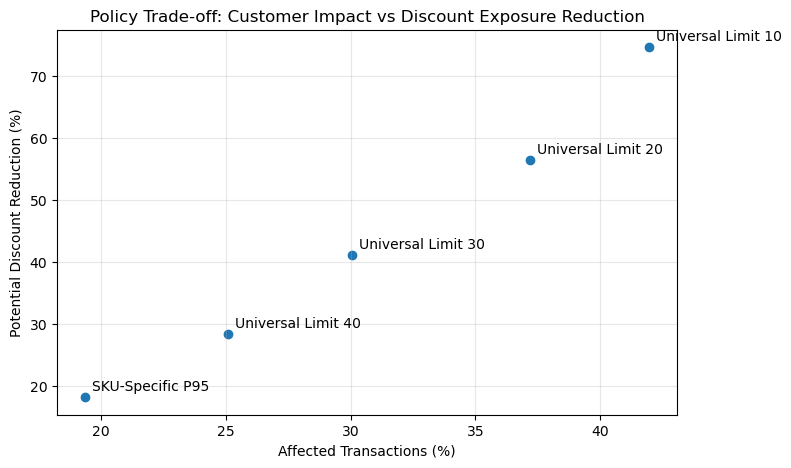

In [214]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    policy_comparison['affected_transactions_pct'],
    policy_comparison['discount_reduction_pct']
)

for _, row in policy_comparison.iterrows():
    plt.annotate(
        row['policy'],
        (
            row['affected_transactions_pct'],
            row['discount_reduction_pct']
        ),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.xlabel('Affected Transactions (%)')
plt.ylabel('Potential Discount Reduction (%)')
plt.title('Policy Trade-off: Customer Impact vs Discount Exposure Reduction')
plt.grid(True, alpha=0.3)
plt.show()

In [215]:
sku_baseline['transaction_count'].describe()

count     94.000000
mean     484.414894
std       70.150899
min      147.000000
25%      482.000000
50%      497.000000
75%      512.750000
max      554.000000
Name: transaction_count, dtype: float64

In [216]:
sku_baseline[
    ['sku_id', 'product_name', 'transaction_count', 'p95_qty']
].sort_values(
    'transaction_count'
).head(20)

,sku_id,product_name,transaction_count,p95_qty
92,SKU000504,Kopi Kapal Api Sachet,147,76.10
90,SKU000501,Teh Pucuk Harum 350ml,158,77.30
91,SKU000502,Beras Premium 5kg,184,71.40
93,SKU000507,Mie Sedaap Goreng,191,60.50
34,SKU000187,Bimoli Pouch 2000ml,443,58.90
86,SKU000482,Indomie Goreng,453,44.20
11,SKU000058,AQ btl 600,454,49.70
83,SKU000465,AQ btl 600,457,62.20
81,SKU000449,Indm Grg,459,31.10
71,SKU000396,Air Mineral Aqua,461,47.00


In [217]:
print(
    "SKU dengan < 30 transaksi baseline:",
    (sku_baseline['transaction_count'] < 30).sum()
)

print(
    "SKU dengan < 50 transaksi baseline:",
    (sku_baseline['transaction_count'] < 50).sum()
)

print(
    "SKU dengan < 100 transaksi baseline:",
    (sku_baseline['transaction_count'] < 100).sum()
)

SKU dengan < 30 transaksi baseline: 0
SKU dengan < 50 transaksi baseline: 0
SKU dengan < 100 transaksi baseline: 0


eluruh SKU 94 JSM memiliki jumlah transaksi non JSM yang cukup untuk membntuk baseline kuantitas pembelian

jumlah transaksi baseline per SKU berkisar antara 147 hingga 455 transaksi dengan median sekitar 497 transaksi. tidak ada SKU dengan jumlah transaksi baseline di bawah 100

dengan begitu kita tau bahwa estimasi P95 per SKU tidak dibentuk dari sampel yang kecil dan secara praktis cukup stabil untuk di pakai sebagai dasar batas kuantiti promo spesifik per SKU

selain itu ada bariasi nilai P95 antar SKU yang menunjukkan jika karakteristik pembelian normal berbeda antar produk. hal ini mendukung penggunaan batas promo spesifik per SKU dibandingkan satu batas universal pembelian untuk semua produk

In [218]:
sensitivity_cap = sku_baseline[
    ['sku_id', 'p90_qty', 'p95_qty', 'p99_qty']
].copy()

sensitivity_cap['p90_cap'] = np.ceil(
    sensitivity_cap['p90_qty']
).astype(int)

sensitivity_cap['p95_cap'] = np.ceil(
    sensitivity_cap['p95_qty']
).astype(int)

sensitivity_cap['p99_cap'] = np.ceil(
    sensitivity_cap['p99_qty']
).astype(int)

sensitivity_cap.head()

,sku_id,p90_qty,p95_qty,p99_qty,p90_cap,p95_cap,p99_cap
0,SKU000001,24.0,43.35,76.07,24,44,77
1,SKU000002,29.0,58.25,82.75,29,59,83
2,SKU000009,24.0,48.00,80.56,24,48,81
3,SKU000012,24.0,34.85,75.39,24,35,76
4,SKU000017,24.0,57.60,75.06,24,58,76


In [219]:
sensitivity_data = (
    jsm_day_high_volume
    .merge(
        sensitivity_cap[
            ['sku_id', 'p90_cap', 'p95_cap', 'p99_cap']
        ],
        on='sku_id',
        how='left'
    )
    .copy()
)

sensitivity_data = sensitivity_data[
    sensitivity_data['qty'] <= 90
].copy()

sensitivity_data['discount_per_unit'] = (
    sensitivity_data['discount_amount']
    / sensitivity_data['qty']
)

In [220]:
sensitivity_results = []

for percentile in ['p90', 'p95', 'p99']:

    cap_col = f'{percentile}_cap'

    excess_qty = (
        sensitivity_data['qty']
        - sensitivity_data[cap_col]
    ).clip(lower=0)

    affected_transactions = (
        excess_qty > 0
    ).sum()

    affected_pct = (
        affected_transactions
        / len(sensitivity_data)
        * 100
    )

    potential_discount_reduction = (
        excess_qty
        * sensitivity_data['discount_per_unit']
    ).sum()

    reduction_pct = (
        potential_discount_reduction
        / total_jsm_discount
        * 100
    )

    sensitivity_results.append({
        'policy': percentile.upper(),
        'affected_transactions': affected_transactions,
        'affected_transactions_pct': affected_pct,
        'excess_qty': excess_qty.sum(),
        'potential_discount_reduction': potential_discount_reduction,
        'discount_reduction_pct': reduction_pct
    })

sensitivity_analysis = pd.DataFrame(
    sensitivity_results
)

sensitivity_analysis

,policy,affected_transactions,affected_transactions_pct,excess_qty,potential_discount_reduction,discount_reduction_pct
0,P90,17575,32.550516,573117,3.893641e+09,48.841031
1,P95,10453,19.359917,211697,1.451224e+09,18.203855
2,P99,2319,4.295001,13290,9.303298e+07,1.166986


In [221]:
sensitivity_display = sensitivity_analysis.copy()

sensitivity_display[
    'affected_transactions_pct'
] = sensitivity_display[
    'affected_transactions_pct'
].round(2)

sensitivity_display[
    'potential_discount_reduction_billion'
] = (
    sensitivity_display[
        'potential_discount_reduction'
    ] / 1_000_000_000
).round(2)

sensitivity_display[
    'discount_reduction_pct'
] = sensitivity_display[
    'discount_reduction_pct'
].round(2)

sensitivity_display[
    [
        'policy',
        'affected_transactions',
        'affected_transactions_pct',
        'excess_qty',
        'potential_discount_reduction_billion',
        'discount_reduction_pct'
    ]
]

,policy,affected_transactions,affected_transactions_pct,excess_qty,potential_discount_reduction_billion,discount_reduction_pct
0,P90,17575,32.55,573117,3.89,48.84
1,P95,10453,19.36,211697,1.45,18.20
2,P99,2319,4.30,13290,0.09,1.17


In [222]:
category_policy_impact = (
    p95_policy
    .merge(
        alfa_products[
            ['sku_id', 'category']
        ],
        on='sku_id',
        how='left',
        suffixes=('', '_product')
    )
)

In [223]:
p95_policy_category = (
    p95_policy
    .merge(
        alfa_products[
            ['sku_id', 'category']
        ],
        on='sku_id',
        how='left'
    )
)

p95_policy_category[
    ['sku_id', 'category']
].head()

,sku_id,category
0,SKU000262,Food & Staples
1,SKU000437,Food & Staples
2,SKU000264,Food & Staples
3,SKU000182,Food & Staples
4,SKU000049,Food & Staples


In [224]:
category_policy_impact = (
    p95_policy_category
    .groupby('category')
    .agg(
        total_transactions=(
            'receipt_id',
            'count'
        ),
        affected_transactions=(
            'excess_qty_p95',
            lambda x: (x > 0).sum()
        ),
        total_excess_qty=(
            'excess_qty_p95',
            'sum'
        ),
        potential_discount_reduction=(
            'potential_discount_reduction',
            'sum'
        ),
        total_discount=(
            'discount_amount',
            'sum'
        )
    )
    .reset_index()
)

In [225]:
category_policy_impact[
    'affected_transactions_pct'
] = (
    category_policy_impact[
        'affected_transactions'
    ]
    / category_policy_impact[
        'total_transactions'
    ]
    * 100
)

category_policy_impact[
    'discount_reduction_pct'
] = (
    category_policy_impact[
        'potential_discount_reduction'
    ]
    / category_policy_impact[
        'total_discount'
    ]
    * 100
)

In [226]:
category_policy_impact[
    [
        'category',
        'total_transactions',
        'affected_transactions',
        'affected_transactions_pct',
        'total_excess_qty',
        'potential_discount_reduction',
        'total_discount',
        'discount_reduction_pct'
    ]
].sort_values(
    'potential_discount_reduction',
    ascending=False
)

,category,total_transactions,affected_transactions,affected_transactions_pct,total_excess_qty,potential_discount_reduction,total_discount,discount_reduction_pct
2,Food & Staples,33423,6316,18.897167,127600,968159964.0,5.400066e+09,17.928667
0,Beverage,11883,2314,19.473197,45382,265909951.0,1.447133e+09,18.374948
3,Personal Care,7567,1599,21.131228,34173,190190403.0,9.583945e+08,19.844688
1,Cigarettes,1120,224,20.000000,4542,26963880.0,1.664765e+08,16.196812


In [227]:
category_policy_display = (
    category_policy_impact.copy()
)

category_policy_display[
    'potential_discount_reduction_billion'
] = (
    category_policy_display[
        'potential_discount_reduction'
    ] / 1_000_000_000
).round(2)

category_policy_display[
    'total_discount_billion'
] = (
    category_policy_display[
        'total_discount'
    ] / 1_000_000_000
).round(2)

category_policy_display[
    'affected_transactions_pct'
] = category_policy_display[
    'affected_transactions_pct'
].round(2)

category_policy_display[
    'discount_reduction_pct'
] = category_policy_display[
    'discount_reduction_pct'
].round(2)

category_policy_display[
    [
        'category',
        'total_transactions',
        'affected_transactions',
        'affected_transactions_pct',
        'total_excess_qty',
        'potential_discount_reduction_billion',
        'total_discount_billion',
        'discount_reduction_pct'
    ]
].sort_values(
    'potential_discount_reduction_billion',
    ascending=False
)

,category,total_transactions,affected_transactions,affected_transactions_pct,total_excess_qty,potential_discount_reduction_billion,total_discount_billion,discount_reduction_pct
2,Food & Staples,33423,6316,18.90,127600,0.97,5.40,17.93
0,Beverage,11883,2314,19.47,45382,0.27,1.45,18.37
3,Personal Care,7567,1599,21.13,34173,0.19,0.96,19.84
1,Cigarettes,1120,224,20.00,4542,0.03,0.17,16.20


In [228]:
p95_policy_store = (
    p95_policy
    .merge(
        alfa_stores[
            [
                'store_id',
                'city',
                'province',
                'store_type',
                'store_format'
            ]
        ],
        on='store_id',
        how='left'
    )
)

p95_policy_store[
    [
        'store_id',
        'store_type',
        'store_format'
    ]
].head()

,store_id,store_type,store_format
0,SAT-0386,Dekat Pasar/Grosir,Sedang (Reguler)
1,SAT-0665,Residential/Perumahan,Sedang (Reguler)
2,SAT-0324,Residential/Perumahan,Kecil (Express)
3,SAT-0325,Perkantoran,Sedang (Reguler)
4,SAT-0119,Residential/Perumahan,Sedang (Reguler)


In [229]:
print(
    "Missing store_type:",
    p95_policy_store['store_type'].isna().sum()
)

print(
    "Missing store_format:",
    p95_policy_store['store_format'].isna().sum()
)

Missing store_type: 0
Missing store_format: 0


In [230]:
store_type_policy_impact = (
    p95_policy_store
    .groupby('store_type')
    .agg(
        total_transactions=(
            'receipt_id',
            'count'
        ),
        affected_transactions=(
            'excess_qty_p95',
            lambda x: (x > 0).sum()
        ),
        total_excess_qty=(
            'excess_qty_p95',
            'sum'
        ),
        potential_discount_reduction=(
            'potential_discount_reduction',
            'sum'
        ),
        total_discount=(
            'discount_amount',
            'sum'
        )
    )
    .reset_index()
)

In [231]:
store_type_policy_impact[
    'affected_transactions_pct'
] = (
    store_type_policy_impact[
        'affected_transactions'
    ]
    / store_type_policy_impact[
        'total_transactions'
    ]
    * 100
)

store_type_policy_impact[
    'discount_reduction_pct'
] = (
    store_type_policy_impact[
        'potential_discount_reduction'
    ]
    / store_type_policy_impact[
        'total_discount'
    ]
    * 100
)

In [232]:
store_type_policy_display = (
    store_type_policy_impact.copy()
)

store_type_policy_display[
    'potential_discount_reduction_million'
] = (
    store_type_policy_display[
        'potential_discount_reduction'
    ] / 1_000_000
).round(2)

store_type_policy_display[
    'affected_transactions_pct'
] = (
    store_type_policy_display[
        'affected_transactions_pct'
    ].round(2)
)

store_type_policy_display[
    'discount_reduction_pct'
] = (
    store_type_policy_display[
        'discount_reduction_pct'
    ].round(2)
)

store_type_policy_display[
    [
        'store_type',
        'total_transactions',
        'affected_transactions',
        'affected_transactions_pct',
        'total_excess_qty',
        'potential_discount_reduction_million',
        'discount_reduction_pct'
    ]
].sort_values(
    'potential_discount_reduction_million',
    ascending=False
)

,store_type,total_transactions,affected_transactions,affected_transactions_pct,total_excess_qty,potential_discount_reduction_million,discount_reduction_pct
0,Dekat Pasar/Grosir,22983,10453,45.48,211697,1451.22,19.99
1,Perkantoran,5517,0,0.00,0,0.00,0.00
2,Residential/Perumahan,25493,0,0.00,0,0.00,0.00


In [233]:
store_type_check = (
    p95_policy_store
    .assign(
        affected_p95=lambda x: x['excess_qty_p95'] > 0
    )
    .groupby('store_type')
    .agg(
        total_transactions=('receipt_id', 'count'),
        affected_transactions=('affected_p95', 'sum'),
        min_qty=('qty', 'min'),
        median_qty=('qty', 'median'),
        mean_qty=('qty', 'mean'),
        max_qty=('qty', 'max'),
        unique_stores=('store_id', 'nunique')
    )
    .reset_index()
)

store_type_check[
    'affected_pct'
] = (
    store_type_check['affected_transactions']
    / store_type_check['total_transactions']
    * 100
).round(2)

store_type_check

,store_type,total_transactions,affected_transactions,min_qty,median_qty,mean_qty,max_qty,unique_stores,affected_pct
0,Dekat Pasar/Grosir,22983,10453,1,48.0,46.865857,89,79,45.48
1,Perkantoran,5517,0,1,2.0,3.401486,24,163,0.00
2,Residential/Perumahan,25493,0,1,2.0,3.354215,24,761,0.00


In [234]:
final_kpi = pd.DataFrame({
    'Metric': [
        'Raw POS Transactions',
        'Analytical Transactions',
        'JSM Promo Products',
        'High-Volume Rate - JSM Day',
        'High-Volume Rate - Non-JSM Day',
        'JSM vs Non-JSM High-Volume Ratio',
        'Total JSM Discount Exposure',
        'High-Volume Discount Exposure',
        'High-Volume Share of JSM Discount',
        'Repeat High-Volume Members',
        'P95 Policy - Affected Transactions',
        'P95 Policy - Affected Transactions (%)',
        'P95 Policy - Total Excess Quantity',
        'P95 Policy - Potential Discount Exposure Reduction',
        'P95 Policy - Discount Exposure Reduction (%)',
        'P95 Affected Transactions in Near-Market/Wholesale Stores (%)'
    ],

    'Value': [
        len(alfa_pos_transactions),
        len(alfa_pos_transactions_analysis),
        sku_baseline['sku_id'].nunique(),
        '25.06%',
        '6.46%',
        '3.88x',
        f"Rp {total_jsm_discount/1e9:.2f} B",
        f"Rp {high_volume_discount/1e9:.2f} B",
        '74.14%',
        len(repeat_high_volume_members),
        10453,
        '19.36%',
        211697,
        'Rp 1.45 B',
        '18.20%',
        '45.48%'
    ]
})

final_kpi

,Metric,Value
0,Raw POS Transactions,455148
1,Analytical Transactions,446034
2,JSM Promo Products,94
3,High-Volume Rate - JSM Day,25.06%
4,High-Volume Rate - Non-JSM Day,6.46%
5,JSM vs Non-JSM High-Volume Ratio,3.88x
6,Total JSM Discount Exposure,Rp 7.97 B
7,High-Volume Discount Exposure,Rp 5.91 B
8,High-Volume Share of JSM Discount,74.14%
9,Repeat High-Volume Members,893


In [235]:
final_kpi.style.hide(axis='index')

Metric,Value
Raw POS Transactions,455148
Analytical Transactions,446034
JSM Promo Products,94
High-Volume Rate - JSM Day,25.06%
High-Volume Rate - Non-JSM Day,6.46%
JSM vs Non-JSM High-Volume Ratio,3.88x
Total JSM Discount Exposure,Rp 7.97 B
High-Volume Discount Exposure,Rp 5.91 B
High-Volume Share of JSM Discount,74.14%
Repeat High-Volume Members,893


## Business Recommendation

Berdasarkan behavioral analysis, financial exposure assessment, policy simulation, dan sensitivity analysis, rekomendasi utama adalah menerapkan SKU-specific promotional quantity cap berbasis P95 dari distribusi pembelian masing-masing SKU pada Non-JSM Day.

Dalam skema ini, customer tetap dapat membeli quantity di atas batas P95, tetapi unit yang melebihi promotional cap tidak lagi memperoleh diskon JSM dan dikenakan harga reguler.

1. Implementasi SKU spesifik P95 promosi cap

P95 dipilih karena memberikan trade-off yang lebih seimbang dibandingkan alternatif P90 dan P99.

Hasil sensitivity analysis menunjukkan:
- P90 memengaruhi sekitar 32,55% transaksi dan berpotensi mengurangi promotional discount exposure sekitar Rp3,89 miliar atau 48,84%
- P95 memengaruhi sekitar 19,36% transaksi dan berpotensi mengurangi promotional discount exposure sekitar Rp1,45 miliar atau 18,20%
- P99 hanya memengaruhi sekitar 4,30% transaksi dan mengurangi promotional discount exposure sekitar Rp0,09 miliar atau 1,17%

Dengan demikian, P90 relatif agresif karena memengaruhi hampir sepertiga transaksi, sedangkan P99 terlalu longgar untuk memberikan dampak finansial yang berarti. P95 memberikan posisi yang lebih moderat antara customer impact dan promotional discount protection.

2. Penetapan cap pada SKU Level

Batas promo sebaiknya berbeda untuk setiap SKU karena karakteristik quantity purchase normal berbeda antarproduk

Seluruh 94 SKU JSM memiliki data baseline Non-JSM yang memadai, dengan jumlah transaksi baseline antara 147 hingga 554 transaksi per SKU dan median sekitar 497 transaksi.

Hal ini mendukung penggunaan P95 per SKU dibandingkan satu universal purchase limit untuk seluruh produk.

3. Prioritas pada store dekat pasar

Implementasi atau pilot awal sebaiknya diprioritaskan pada store bertipe `Dekat Pasar/Grosir`.

Analisis store type menunjukkan:
- sekitar 45,48% transaksi JSM pada store `Dekat Pasar/Grosir` berada di atas promotional cap P95
- tidak ditemukan transaksi terdampak pada store `Perkantoran`
- tidak ditemukan transaksi terdampak pada store `Residential/Perumahan`

Distribusi quantity juga berbeda secara jelas. Median quantity pada store `Dekat Pasar/Grosir` mencapai sekitar 48 unit, sedangkan median pada dua tipe store lainnya hanya sekitar 2 unit

Dengan demikian, kebutuhan pengendalian promotional quantity tidak tersebar merata di seluruh jaringan store

4. Unit di atas batas menggunakan harga reguler

Kebijakan tidak disarankan dalam bentuk hard purchase limit

Customer tetap dapat membeli unit di atas P95 cap, tetapi unit tersebut tidak lagi menerima Promo JSM

pendekatan ini menjaga peluang penjualan sambil mengurangi promotional discount exposure pada quantity yang berada di atas pola pembelian normal

5. Menggunakan implementasi piloting dengan monitoring ketat

Sebelum implementasi lebih luas, kebijakan sebaiknya diuji pada store `Dekat Pasar/Grosir`

Monitoring pilot dapat mencakup:
- promotional discount exposure
- unit sales
- basket size
- transaksi terdampak
- customer complaints
- perubahan pola splitting transaction
- serta perpindahan pembelian ke store lain

P95 juga perlu dihitung ulang secara periodik agar tetap merefleksikan perubahan pola pembelian normal masing-masing SKU.

6. Kenapa menggunakan promo ny kuantitas?

High-volume purchase tidak sebaiknya langsung dikategorikan sebagai reseller activity

Walaupun high-volume purchase meningkat pada JSM Day, repeat-member analysis menunjukkan bahwa sebagian besar perilaku tersebut bersifat sporadis dan tidak konsisten pada SKU, store, maupun interval transaksi.

Oleh karena itu, intervensi lebih tepat dilakukan pada **promo eligibility by quantity** daripada melalui pelabelan customer.

In [236]:
recommended_policy = sku_baseline[
    [
        'sku_id',
        'product_name',
        'category',
        'brand',
        'transaction_count',
        'median_qty',
        'p95_qty',
        'p95_cap',
        'jsm_discount_pct'
    ]
].copy()

recommended_policy = recommended_policy.sort_values(
    'p95_cap'
)

recommended_policy.head(20)

,sku_id,product_name,category,brand,transaction_count,median_qty,p95_qty,p95_cap,jsm_discount_pct
81,SKU000449,Indm Grg,Food & Staples,Indofood,459,2.0,31.10,32,0.31
3,SKU000012,Pepsodent 190g,Personal Care,Unilever,524,2.0,34.85,35,0.19
78,SKU000445,AQ btl 600,Beverage,Danone-Aqua,508,2.0,35.30,36,0.31
23,SKU000131,Mnyk Goreng Bimoli,Food & Staples,Salim Ivomas,491,2.0,38.00,38,0.21
85,SKU000477,INDOMIE MIE GORENG,Food & Staples,Indofood,485,2.0,38.80,39,0.23
38,SKU000214,Bimoli Pouch 2000ml,Food & Staples,Salim Ivomas,532,2.0,40.45,41,0.32
87,SKU000484,INDOMIE MIE GORENG,Food & Staples,Indofood,505,2.0,40.80,41,0.29
42,SKU000233,Rokok Sampoerna Mild,Cigarettes,Sampoerna,510,2.0,42.00,42,0.31
36,SKU000206,Bimoli Pouch 2000ml,Food & Staples,Salim Ivomas,501,2.0,42.00,42,0.25
50,SKU000282,Pepsodent 190g,Personal Care,Unilever,508,2.0,41.60,42,0.36


In [237]:
recommended_policy.to_csv(
    'recommended_jsm_promo_cap_by_sku.csv',
    index=False
)

## Conclusion

Analisis menunjukkan bahwa Promo JSM berkaitan dengan peningkatan high-volume purchase pada produk JSM

Proporsi transaksi high-volume mencapai sekitar 25,06% pada JSM Day dibandingkan sekitar 6,46% pada Non-JSM Day atau sekitar 3,88 kali lebih tinggi

Dari total promotional discount exposure sekitar Rp7,97 miliar sekitar 74,14 berasal dari transaksi high-volume. Namun, repeat-member analysis menunjukkan bahwa sebagian besar perilaku high-volume bersifat sporadis dan tidak cukup konsisten untuk langsung dikategorikan sebagai reseller activity

Simulasi kebijakan menunjukkan bahwa SKU-specific P95 promotional cap memberikan pendekatan yang lebih seimbang dibandingkan P90 dan P99. Kebijakan P95 diperkirakan:
- memengaruhi sekitar 19,36% transaksi JSM
- membatasi sekitar 211.697 excess units dari eligibility promo
- dan berpotensi mengurangi promotional discount exposure sekitar Rp1,45 miliar atau 18,20 dari total JSM discount exposure

Dampak kebijakan juga sangat terkonsentrasi pada store bertipe Dekat Pasar/Grosir di mana sekitar 45,48% transaksi JSM berada di atas P95 promotional cap. Sebaliknya, tidak ditemukan transaksi terdampak pada store Perkantoran maupun Residential/Perumahan.

Berdasarkan temuan tersebut, pendekatan yang direkomendasikan adalah SKU-specific P95 promotional cap dengan unit di atas batas promo tetap dapat dibeli pada harga reguler. Implementasi awal sebaiknya dilakukan melalui pilot pada store bertipe Dekat Pasar/Grosir dan dievaluasi secara berkala sebelum perluasan ke jaringan yang lebih luas.